# Phase 10 — CLEAN-v3 KUB Baseline Comparison (FINAL, four models)

**Model:** Gemini 3.1 Pro High
**Date:** 2026-09-21
**Manifest:** `phase4_v3` | **Taxonomy:** `kub_size_clean_v3_v1`

Compares four already-frozen clean-v3 KUB baseline runs:

| Model | Experiment | Best epoch | VAL Dice |
|---|---|---|---|
| UNet | `phase9_kub_unet_baseline_seed42_512_clean_v3` | 44 | 0.7406133413314819 |
| Attention U-Net | `phase10_kub_attention_unet_seed42_512_clean_v3` | 54 | 0.7525129853960107 |
| UNet++ | `phase10_kub_unetpp_seed42_512_clean_v3` | 70 | 0.7641595156062713 |
| DeepLabV3+ | `phase10_kub_deeplabv3plus_seed42_512_clean_v3` | 52 | 0.7509140344161673 |

---

> **READ-ONLY.** No retraining, no checkpoint writes, no config changes, no threshold
> tuning, no TEST access.
>
> **NO WINNER IS DECLARED.** All runs are **single-seed (42) descriptive VAL evidence**.
> No statistical significance testing has been performed (Phase 29 / Phase 31 have not run).
> **TEST remains locked until Phase 39.**
>
> The ordering of rows in tables below is bookkeeping, **not a ranking**.


## 2. Scientific Objective

Produce a rigorous **descriptive** clean-v3 comparison of four KUB baseline architectures on
identical data and protocol, then close Phase 10.

Specifically:
1. Verify all four frozen runs are intact (immutability by SHA).
2. Confirm the four runs are scientifically comparable (same data, protocol, target, seed).
3. Reconstruct **complete epoch-by-epoch tables** for every model (one row per epoch).
4. Re-run read-only inference on the **same 280 KUB VAL cases** with all four `best.pt`.
5. Reproduce the authoritative aggregate metrics from the paired table.
6. Report category- and acquisition-stratified results, plus descriptive paired deltas.
7. Show a frozen 16-case paired qualitative comparison.

**Non-objectives:** declaring a winner, significance testing, ranking, touching TEST,
starting Phase 11.


## 3. Governance and TEST Lock

| Rule | Status |
|---|---|
| TEST image/mask/content reads | **0** |
| TEST metrics / visualizations | **0** |
| TEST dataset instantiated | **NO** |
| Retraining | **NO** |
| Checkpoint / history / config modification | **NO** |
| Threshold tuning | **NO** (fixed 0.5) |
| Statistical significance testing | **NOT PERFORMED** |
| Winner declaration | **NO** |
| Phase 11 | **NOT STARTED** |

`KUBDataset` blocks TEST construction unless `allow_test=True`, which is never set here.


## 4. Four Frozen Experiments


In [1]:
%matplotlib inline
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

# FULL display of all epoch rows - hard requirement
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
pd.set_option('display.max_colwidth', None)

PROJECT_ROOT = Path(r'D:\Softfors\jup')
sys.path.insert(0, str(PROJECT_ROOT))
sys.path.insert(0, str(PROJECT_ROOT / 'notebooks' / 'phasewise' / 'phase_10_baseline_comparison' / 'code'))
import phase10_final_comparison as fc

for k in fc.MODEL_ORDER:
    m = fc.MODELS[k]
    a = m['authoritative']
    print(f"{m['display']:16s} {m['experiment_id']}")
    print(f"{'':16s} best_ep={m['expected_best_epoch']}  Dice={a['dice']:.16f}  IoU={a['iou']:.16f}")
    print(f"{'':16s} Prec={a['precision']:.16f}  Recall={a['recall']:.16f}")
    print()


UNet             phase9_kub_unet_baseline_seed42_512_clean_v3
                 best_ep=44  Dice=0.7406133413314819  IoU=0.6253822445869446
                 Prec=0.7707186937332153  Recall=0.7839437127113342

Attention U-Net  phase10_kub_attention_unet_seed42_512_clean_v3
                 best_ep=54  Dice=0.7525129853960107  IoU=0.6349387691368995
                 Prec=0.7729140812402236  Recall=0.7922248481868364

UNet++           phase10_kub_unetpp_seed42_512_clean_v3
                 best_ep=70  Dice=0.7641595156062713  IoU=0.6525442690586191
                 Prec=0.7996825971468945  Recall=0.7912384169561990

DeepLabV3+       phase10_kub_deeplabv3plus_seed42_512_clean_v3
                 best_ep=52  Dice=0.7509140344161673  IoU=0.6460492792430865
                 Prec=0.7943328495850855  Recall=0.7822983241135557



## 5. Artifact Immutability Verification


In [2]:
imm = fc.verify_immutability()
rows=[]
for k,v in imm.items():
    rows.append({'model': fc.MODELS[k]['display'], 'experiment_id': v['experiment_id'],
                 'history_sha': v['history_sha'][:16]+'...', 'history_match': v['history_sha_match'],
                 'best_sha': v['best_sha'][:16]+'...', 'best_match': v['best_sha_match'],
                 'latest_sha': v['latest_sha'][:16]+'...',
                 'reviewer_nb_sha': v['reviewer_notebook_sha'][:16]+'...'})
display(pd.DataFrame(rows))
assert all(v['all_match'] for v in imm.values()), 'Immutability FAILED - CHECK_REQUIRED'
print('\nALL FOUR RUNS IMMUTABLE - PASS')


,model,experiment_id,history_sha,history_match,best_sha,best_match,latest_sha,reviewer_nb_sha
0,UNet,phase9_kub_unet_baseline_seed42_512_clean_v3,7678a5822542cd35...,True,7b955ba86464a2fe...,True,6de118bf21cacd56...,60466fa12170f6ac...
1,Attention U-Net,phase10_kub_attention_unet_seed42_512_clean_v3,ee5073f0bea74528...,True,a49b19d66e43b57e...,True,74a7e612ac9d6a2f...,71ae94180551c96f...
2,UNet++,phase10_kub_unetpp_seed42_512_clean_v3,a733d8366278d2dd...,True,ec7eb13f32e43af2...,True,77a39b4f510f6995...,0fd9176fb82340b7...
3,DeepLabV3+,phase10_kub_deeplabv3plus_seed42_512_clean_v3,9c3a4611f0f38b47...,True,f519027ba1a3a4d6...,True,69267fd0cd2104cb...,17942c35387a5935...



ALL FOUR RUNS IMMUTABLE - PASS


## 6. Protocol Comparability

All four runs share the same data and training protocol; the only scientific difference is
**architecture**.


In [3]:
prot=[]
for k in fc.MODEL_ORDER:
    cfg = fc.yaml.safe_load(fc.MODELS[k]['config'].read_text(encoding='utf-8'))
    t, m = cfg['training'], cfg['model']
    prot.append({'model': fc.MODELS[k]['display'],
        'manifest': cfg['manifest_version'], 'taxonomy': cfg['taxonomy_id'],
        'resolution': cfg['input_resolution'], 'in_ch': m['input_channels'], 'out_ch': m['output_channels'],
        'loss': f"{cfg['loss']['name']} {cfg['loss']['bce_weight']}/{cfg['loss']['dice_weight']}",
        'optimizer': cfg['optimizer']['name'], 'lr': cfg['optimizer']['learning_rate'],
        'wd': cfg['optimizer']['weight_decay'],
        'scheduler': f"{cfg['scheduler']['name']} T_max={cfg['scheduler']['max_epochs']}",
        'batch': t['batch_size'], 'accum': t['gradient_accumulation_steps'],
        'amp': t['amp'], 'seed': t['seed'], 'max_epochs': t['max_epochs'],
        'patience': t['early_stopping_patience'], 'threshold': t['threshold'],
        'monitor': t['monitor'], 'allow_test': cfg['allow_test']})
P = pd.DataFrame(prot)
display(P.set_index('model').T)

# gates
assert (P['manifest']=='phase4_v3').all()
assert (P['taxonomy']=='kub_size_clean_v3_v1').all()
assert (P['resolution']==512).all() and (P['in_ch']==1).all() and (P['out_ch']==1).all()
assert (P['seed']==42).all() and (P['threshold']==0.5).all()
assert (~P['allow_test']).all()
print('\nCOMPARABILITY - PASS (identical data/protocol; only architecture differs)')


model,UNet,Attention U-Net,UNet++,DeepLabV3+
manifest,phase4_v3,phase4_v3,phase4_v3,phase4_v3
taxonomy,kub_size_clean_v3_v1,kub_size_clean_v3_v1,kub_size_clean_v3_v1,kub_size_clean_v3_v1
resolution,512,512,512,512
in_ch,1,1,1,1
out_ch,1,1,1,1
loss,bce_dice 0.5/0.5,bce_dice 0.5/0.5,bce_dice 0.5/0.5,bce_dice 0.5/0.5
optimizer,AdamW,AdamW,AdamW,AdamW
lr,0.0001,0.0001,0.0001,0.0001
wd,0.0001,0.0001,0.0001,0.0001
scheduler,CosineAnnealingLR T_max=100,CosineAnnealingLR T_max=100,CosineAnnealingLR T_max=100,CosineAnnealingLR T_max=100



COMPARABILITY - PASS (identical data/protocol; only architecture differs)


## 7. Epoch-Table Normalization Contract

Physical histories use slightly different column names:
Phase 09 uses `val_macro_dice`, Phase 10 uses `val_dice`. Reviewer tables normalise to
canonical names. **Original history files are never modified.** No metric is fabricated —
unavailable fields are `N/A`.

Derived reviewer-only columns: `delta_val_dice_vs_previous_epoch`, `delta_best_metric`,
`is_new_best`, `is_best_epoch`, `epochs_since_best`.


In [4]:
tables = {k: fc.build_epoch_table(k) for k in fc.MODEL_ORDER}
vers   = {k: fc.verify_epoch_table(k, tables[k]) for k in fc.MODEL_ORDER}
paths  = {k: fc.save_epoch_table(k, tables[k]) for k in fc.MODEL_ORDER}
for k in fc.MODEL_ORDER:
    p = paths[k]
    print(f"{fc.MODELS[k]['display']:16s} -> {p.name}  SHA {fc.sha256_file(p)}")
long = fc.build_long_table(tables)
lp = fc.TABLES / 'phase10_final_all_models_epoch_results_long.csv'
long.to_csv(lp, index=False)
print(f"\nMODEL_EPOCH_LONG_TABLE -> {lp.name}  rows={len(long)}  SHA {fc.sha256_file(lp)}")
assert len(long) == 280, f'long table must be 280 rows, got {len(long)}'
print('NOTE: 280 here = 59+69+85+67 MODEL-EPOCH rows, distinct from the 280 VAL cases.')


UNet             -> phase10_final_epoch_results_unet.csv  SHA 484d27507bd0493235a5fd889943b29101fabc0c5b2e1e7ca3f4541cf9df2ba8
Attention U-Net  -> phase10_final_epoch_results_attention_unet.csv  SHA 2aecdb5e4fcb8cae1fa09864e17bbe5f50afe9d40ff09794364456d086255fd2
UNet++           -> phase10_final_epoch_results_unetpp.csv  SHA 2dd885d27788e5981a9356cf3e1f518d55eaff61d34f061eee92660beed505d4
DeepLabV3+       -> phase10_final_epoch_results_deeplabv3plus.csv  SHA f0f5750025d0cfb8706c35958d3e76b28a3246105184bd715e161332bfcd19a2

MODEL_EPOCH_LONG_TABLE -> phase10_final_all_models_epoch_results_long.csv  rows=280  SHA 9057cdd428995b88bf0c527152d072398573892649baebea5b4082de2b6476ca
NOTE: 280 here = 59+69+85+67 MODEL-EPOCH rows, distinct from the 280 VAL cases.


## 8. Complete Epoch Table — UNet

Every completed epoch is displayed below (**untruncated**).


In [5]:
t = tables['unet']
v = vers['unet']
print('=== INTEGRITY: UNet ===')
for kk, vv in v.items(): print(f'  {kk}: {vv}')
print()
assert v['integrity_pass'] and v['row_count_matches_history']
print(f"Rendering ALL {len(t)} epoch rows for UNet:")
display(t)


=== INTEGRITY: UNet ===
  model: UNet
  rows: 59
  history_rows: 59
  row_count_matches_history: True
  unique_epochs: 59
  first_epoch: 1
  last_epoch: 59
  missing_epochs: []
  duplicate_epochs: []
  contiguous_1_to_N: True
  best_epoch: 44
  strict_unique_max: True
  final_bad_epochs: 15
  early_stop_arithmetic_ok: True
  improvement_events: 21
  longest_no_improvement_streak: 15
  final_lr: 3.6050444698038574e-05
  best_lr: 5.9369065729286285e-05
  finite_losses: True
  integrity_pass: True

Rendering ALL 59 epoch rows for UNet:


,model,experiment_id,epoch,train_loss,val_loss,val_macro_dice,val_macro_iou,val_precision,val_recall,learning_rate,best_metric_so_far,improved,bad_epochs,elapsed_seconds,checkpoint_event,delta_val_dice_vs_previous_epoch,delta_best_metric,is_new_best,is_best_epoch,epochs_since_best
0,UNet,phase9_kub_unet_baseline_seed42_512_clean_v3,1,0.442458,0.465926,0.431176,0.340278,N/A,N/A,0.000100,NaN,1,0,268.742252,BEST_SAVED,NaN,NaN,True,False,0
1,UNet,phase9_kub_unet_baseline_seed42_512_clean_v3,2,0.392092,0.396965,0.456776,0.366742,N/A,N/A,0.000100,NaN,1,0,60.102438,BEST_SAVED,0.025599,NaN,True,False,0
2,UNet,phase9_kub_unet_baseline_seed42_512_clean_v3,3,0.367363,0.359159,0.490891,0.401569,N/A,N/A,0.000100,NaN,1,0,60.311679,BEST_SAVED,0.034116,NaN,True,False,0
3,UNet,phase9_kub_unet_baseline_seed42_512_clean_v3,4,0.351135,0.425429,0.497879,0.397826,N/A,N/A,0.000100,NaN,1,0,60.858533,BEST_SAVED,0.006987,NaN,True,False,0
4,UNet,phase9_kub_unet_baseline_seed42_512_clean_v3,5,0.335718,0.332848,0.530259,0.438920,N/A,N/A,0.000099,NaN,1,0,63.602900,BEST_SAVED,0.032380,NaN,True,False,0
5,UNet,phase9_kub_unet_baseline_seed42_512_clean_v3,6,0.321234,0.321200,0.545095,0.452030,N/A,N/A,0.000099,NaN,1,0,63.525723,BEST_SAVED,0.014836,NaN,True,False,0
6,UNet,phase9_kub_unet_baseline_seed42_512_clean_v3,7,0.306985,0.305672,0.579637,0.472824,N/A,N/A,0.000099,NaN,1,0,64.249523,BEST_SAVED,0.034542,NaN,True,False,0
7,UNet,phase9_kub_unet_baseline_seed42_512_clean_v3,8,0.292267,0.391134,0.563304,0.445191,N/A,N/A,0.000098,NaN,0,1,63.671509,LATEST_ONLY,-0.016333,NaN,False,False,1
8,UNet,phase9_kub_unet_baseline_seed42_512_clean_v3,9,0.272067,0.287922,0.638627,0.520392,N/A,N/A,0.000098,NaN,1,0,63.566675,BEST_SAVED,0.075323,NaN,True,False,0
9,UNet,phase9_kub_unet_baseline_seed42_512_clean_v3,10,0.261210,0.260292,0.654405,0.541183,N/A,N/A,0.000098,NaN,1,0,63.609702,BEST_SAVED,0.015778,NaN,True,False,0


## 9. Complete Epoch Table — Attention U-Net

Every completed epoch is displayed below (**untruncated**).


In [6]:
t = tables['attention_unet']
v = vers['attention_unet']
print('=== INTEGRITY: Attention U-Net ===')
for kk, vv in v.items(): print(f'  {kk}: {vv}')
print()
assert v['integrity_pass'] and v['row_count_matches_history']
print(f"Rendering ALL {len(t)} epoch rows for Attention U-Net:")
display(t)


=== INTEGRITY: Attention U-Net ===
  model: Attention U-Net
  rows: 69
  history_rows: 69
  row_count_matches_history: True
  unique_epochs: 69
  first_epoch: 1
  last_epoch: 69
  missing_epochs: []
  duplicate_epochs: []
  contiguous_1_to_N: True
  best_epoch: 54
  strict_unique_max: True
  final_bad_epochs: 15
  early_stop_arithmetic_ok: True
  improvement_events: 24
  longest_no_improvement_streak: 15
  final_lr: 2.189583110739349e-05
  best_lr: 4.373333832178482e-05
  finite_losses: True
  integrity_pass: True

Rendering ALL 69 epoch rows for Attention U-Net:


,model,experiment_id,epoch,train_loss,val_loss,val_macro_dice,val_macro_iou,val_precision,val_recall,learning_rate,best_metric_so_far,improved,bad_epochs,elapsed_seconds,checkpoint_event,delta_val_dice_vs_previous_epoch,delta_best_metric,is_new_best,is_best_epoch,epochs_since_best
0,Attention U-Net,phase10_kub_attention_unet_seed42_512_clean_v3,1,0.511852,0.492498,0.455501,0.364793,0.557557,0.601329,0.000100,0.455501,1,0,180.8,BEST_SAVED,NaN,NaN,True,False,0
1,Attention U-Net,phase10_kub_attention_unet_seed42_512_clean_v3,2,0.421238,0.414937,0.453676,0.365484,0.583015,0.572629,0.000100,0.455501,0,1,73.8,LATEST_ONLY,-0.001825,0.000000,False,False,1
2,Attention U-Net,phase10_kub_attention_unet_seed42_512_clean_v3,3,0.385591,0.402041,0.469479,0.383368,0.685439,0.592345,0.000100,0.469479,1,0,70.7,BEST_SAVED,0.015802,0.013977,True,False,0
3,Attention U-Net,phase10_kub_attention_unet_seed42_512_clean_v3,4,0.363607,0.365701,0.492169,0.400162,0.595332,0.512817,0.000100,0.492169,1,0,70.3,BEST_SAVED,0.022690,0.022690,True,False,0
4,Attention U-Net,phase10_kub_attention_unet_seed42_512_clean_v3,5,0.347567,0.357465,0.507544,0.418799,0.459013,0.673806,0.000099,0.507544,1,0,73.2,BEST_SAVED,0.015375,0.015375,True,False,0
5,Attention U-Net,phase10_kub_attention_unet_seed42_512_clean_v3,6,0.335710,0.337032,0.542214,0.445455,0.538902,0.645993,0.000099,0.542214,1,0,73.1,BEST_SAVED,0.034670,0.034670,True,False,0
6,Attention U-Net,phase10_kub_attention_unet_seed42_512_clean_v3,7,0.326942,0.326772,0.546270,0.452797,0.531451,0.653997,0.000099,0.546270,1,0,73.4,BEST_SAVED,0.004056,0.004056,True,False,0
7,Attention U-Net,phase10_kub_attention_unet_seed42_512_clean_v3,8,0.313945,0.307033,0.566118,0.473826,0.656369,0.611473,0.000098,0.566118,1,0,74.5,BEST_SAVED,0.019848,0.019848,True,False,0
8,Attention U-Net,phase10_kub_attention_unet_seed42_512_clean_v3,9,0.299837,0.293197,0.603426,0.499475,0.653554,0.661779,0.000098,0.603426,1,0,74.2,BEST_SAVED,0.037307,0.037307,True,False,0
9,Attention U-Net,phase10_kub_attention_unet_seed42_512_clean_v3,10,0.285437,0.288194,0.604399,0.499341,0.690762,0.631612,0.000098,0.604399,1,0,74.3,BEST_SAVED,0.000973,0.000973,True,False,0


## 10. Complete Epoch Table — UNet++

Every completed epoch is displayed below (**untruncated**).


In [7]:
t = tables['unetpp']
v = vers['unetpp']
print('=== INTEGRITY: UNet++ ===')
for kk, vv in v.items(): print(f'  {kk}: {vv}')
print()
assert v['integrity_pass'] and v['row_count_matches_history']
print(f"Rendering ALL {len(t)} epoch rows for UNet++:")
display(t)


=== INTEGRITY: UNet++ ===
  model: UNet++
  rows: 85
  history_rows: 85
  row_count_matches_history: True
  unique_epochs: 85
  first_epoch: 1
  last_epoch: 85
  missing_epochs: []
  duplicate_epochs: []
  contiguous_1_to_N: True
  best_epoch: 70
  strict_unique_max: True
  final_bad_epochs: 15
  early_stop_arithmetic_ok: True
  improvement_events: 21
  longest_no_improvement_streak: 15
  final_lr: 5.449673790581617e-06
  best_lr: 2.0610737385376376e-05
  finite_losses: True
  integrity_pass: True

Rendering ALL 85 epoch rows for UNet++:


,model,experiment_id,epoch,train_loss,val_loss,val_macro_dice,val_macro_iou,val_precision,val_recall,learning_rate,best_metric_so_far,improved,bad_epochs,elapsed_seconds,checkpoint_event,delta_val_dice_vs_previous_epoch,delta_best_metric,is_new_best,is_best_epoch,epochs_since_best
0,UNet++,phase10_kub_unetpp_seed42_512_clean_v3,1,0.438780,0.416830,0.454545,0.363090,0.678880,0.502299,0.000100,0.454545,1,0,290.9,BEST_SAVED,NaN,NaN,True,False,0
1,UNet++,phase10_kub_unetpp_seed42_512_clean_v3,2,0.388098,0.421986,0.468632,0.378370,0.704706,0.592291,0.000100,0.468632,1,0,180.4,BEST_SAVED,0.014087,0.014087,True,False,0
2,UNet++,phase10_kub_unetpp_seed42_512_clean_v3,3,0.363468,0.443350,0.465154,0.372904,0.571621,0.639822,0.000100,0.468632,0,1,180.6,LATEST_ONLY,-0.003477,0.000000,False,False,1
3,UNet++,phase10_kub_unetpp_seed42_512_clean_v3,4,0.352005,0.348390,0.519276,0.427362,0.499869,0.639654,0.000100,0.519276,1,0,180.6,BEST_SAVED,0.054121,0.050644,True,False,0
4,UNet++,phase10_kub_unetpp_seed42_512_clean_v3,5,0.336932,0.323569,0.554764,0.460919,0.562959,0.635015,0.000099,0.554764,1,0,178.6,BEST_SAVED,0.035489,0.035489,True,False,0
5,UNet++,phase10_kub_unetpp_seed42_512_clean_v3,6,0.325398,0.328325,0.562319,0.462126,0.589963,0.666141,0.000099,0.562319,1,0,178.7,BEST_SAVED,0.007554,0.007554,True,False,0
6,UNet++,phase10_kub_unetpp_seed42_512_clean_v3,7,0.310921,0.328777,0.551526,0.443353,0.545447,0.666942,0.000099,0.562319,0,1,178.6,LATEST_ONLY,-0.010793,0.000000,False,False,1
7,UNet++,phase10_kub_unetpp_seed42_512_clean_v3,8,0.297655,0.320062,0.547991,0.450617,0.499140,0.808599,0.000098,0.562319,0,2,178.9,LATEST_ONLY,-0.003535,0.000000,False,False,2
8,UNet++,phase10_kub_unetpp_seed42_512_clean_v3,9,0.265427,0.276223,0.620099,0.504560,0.570966,0.801323,0.000098,0.620099,1,0,178.9,BEST_SAVED,0.072109,0.057781,True,False,0
9,UNet++,phase10_kub_unetpp_seed42_512_clean_v3,10,0.258951,0.272386,0.659271,0.536225,0.616674,0.808719,0.000098,0.659271,1,0,179.0,BEST_SAVED,0.039172,0.039172,True,False,0


## 11. Complete Epoch Table — DeepLabV3+

Every completed epoch is displayed below (**untruncated**).


In [8]:
t = tables['deeplabv3plus']
v = vers['deeplabv3plus']
print('=== INTEGRITY: DeepLabV3+ ===')
for kk, vv in v.items(): print(f'  {kk}: {vv}')
print()
assert v['integrity_pass'] and v['row_count_matches_history']
print(f"Rendering ALL {len(t)} epoch rows for DeepLabV3+:")
display(t)


=== INTEGRITY: DeepLabV3+ ===
  model: DeepLabV3+
  rows: 67
  history_rows: 67
  row_count_matches_history: True
  unique_epochs: 67
  first_epoch: 1
  last_epoch: 67
  missing_epochs: []
  duplicate_epochs: []
  contiguous_1_to_N: True
  best_epoch: 52
  strict_unique_max: True
  final_bad_epochs: 15
  early_stop_arithmetic_ok: True
  improvement_events: 23
  longest_no_improvement_streak: 15
  final_lr: 2.4547929212481463e-05
  best_lr: 4.686047402353437e-05
  finite_losses: True
  integrity_pass: True

Rendering ALL 67 epoch rows for DeepLabV3+:


,model,experiment_id,epoch,train_loss,val_loss,val_macro_dice,val_macro_iou,val_precision,val_recall,learning_rate,best_metric_so_far,improved,bad_epochs,elapsed_seconds,checkpoint_event,delta_val_dice_vs_previous_epoch,delta_best_metric,is_new_best,is_best_epoch,epochs_since_best
0,DeepLabV3+,phase10_kub_deeplabv3plus_seed42_512_clean_v3,1,0.377359,0.349518,0.487975,0.407391,0.870639,0.504660,0.000100,0.487975,1,0,188.1,BEST_SAVED,NaN,NaN,True,False,0
1,DeepLabV3+,phase10_kub_deeplabv3plus_seed42_512_clean_v3,2,0.330579,0.314964,0.540444,0.460717,0.769889,0.578849,0.000100,0.540444,1,0,74.1,BEST_SAVED,0.052469,0.052469,True,False,0
2,DeepLabV3+,phase10_kub_deeplabv3plus_seed42_512_clean_v3,3,0.307240,0.299174,0.563059,0.480463,0.749197,0.596709,0.000100,0.563059,1,0,73.8,BEST_SAVED,0.022615,0.022615,True,False,0
3,DeepLabV3+,phase10_kub_deeplabv3plus_seed42_512_clean_v3,4,0.287705,0.291801,0.574313,0.487857,0.736589,0.615886,0.000100,0.574313,1,0,74.1,BEST_SAVED,0.011254,0.011254,True,False,0
4,DeepLabV3+,phase10_kub_deeplabv3plus_seed42_512_clean_v3,5,0.273234,0.300474,0.571880,0.480890,0.696173,0.606999,0.000099,0.574313,0,1,73.4,LATEST_ONLY,-0.002432,0.000000,False,False,1
5,DeepLabV3+,phase10_kub_deeplabv3plus_seed42_512_clean_v3,6,0.261933,0.269859,0.602290,0.513627,0.702040,0.631256,0.000099,0.602290,1,0,73.4,BEST_SAVED,0.030410,0.027978,True,False,0
6,DeepLabV3+,phase10_kub_deeplabv3plus_seed42_512_clean_v3,7,0.246003,0.270271,0.610485,0.516051,0.617278,0.741697,0.000099,0.610485,1,0,73.3,BEST_SAVED,0.008194,0.008194,True,False,0
7,DeepLabV3+,phase10_kub_deeplabv3plus_seed42_512_clean_v3,8,0.233239,0.248815,0.645464,0.541690,0.721210,0.702844,0.000098,0.645464,1,0,74.8,BEST_SAVED,0.034979,0.034979,True,False,0
8,DeepLabV3+,phase10_kub_deeplabv3plus_seed42_512_clean_v3,9,0.221540,0.234570,0.669442,0.563907,0.757588,0.721188,0.000098,0.669442,1,0,73.4,BEST_SAVED,0.023978,0.023978,True,False,0
9,DeepLabV3+,phase10_kub_deeplabv3plus_seed42_512_clean_v3,10,0.213646,0.225732,0.683498,0.576951,0.709659,0.729663,0.000098,0.683498,1,0,73.2,BEST_SAVED,0.014057,0.014057,True,False,0


## 12. Training Dynamics (descriptive)

Six panels across all four models. Curves are descriptive — the visually highest curve is
**not** called a winner.


Saved: D:\Softfors\jup\reports\figures\phase10_clean_v3_training_dynamics.png


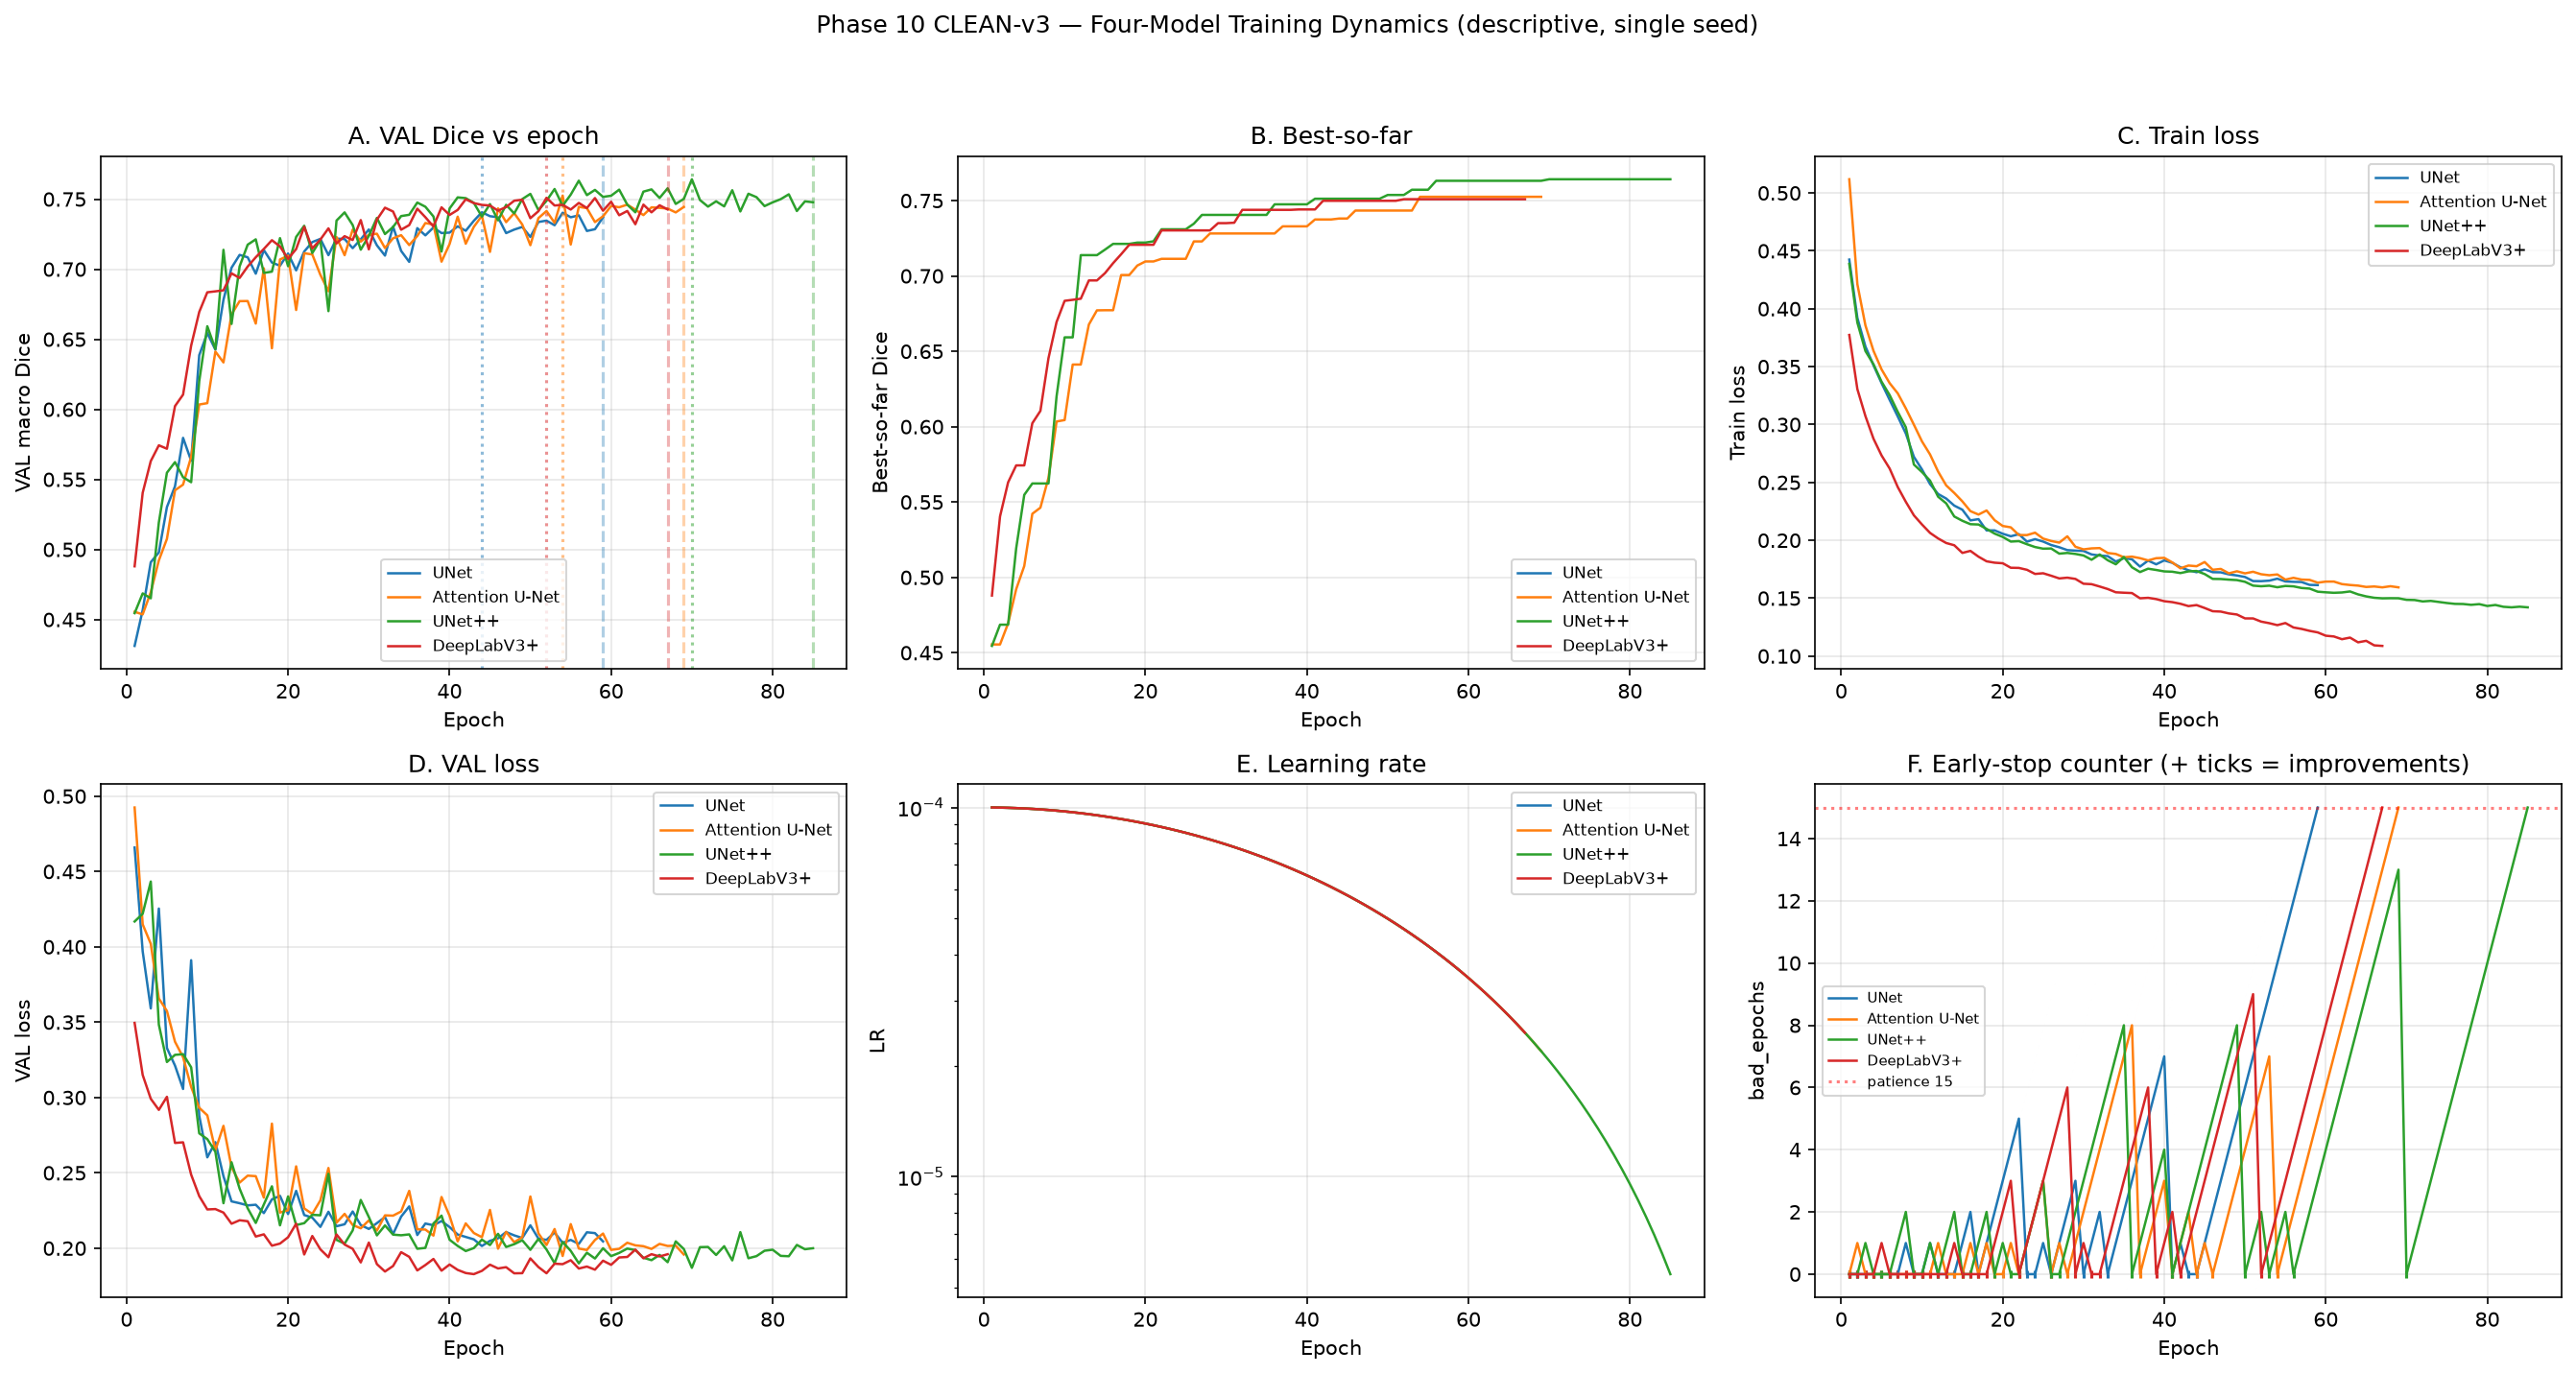

In [9]:
p_dyn = fc.plot_training_dynamics(tables)
print('Saved:', p_dyn)
from IPython.display import Image as IPImage
display(IPImage(filename=str(p_dyn)))


## 13. KUB-Only VAL Population


In [10]:
val = fc.get_kub_val()
print('KUB VAL rows:', len(val))
print('Categories  :', val['category'].value_counts().to_dict())
print('Acquisition :', val['acquisition_type'].value_counts().to_dict())
assert len(val)==280
assert set(val['category'])=={'Kidney_Stone','Bladder_Stone','Ureteric_Stone'}
assert val['acquisition_type'].value_counts().to_dict()=={'ROI':177,'FULL_FIELD':103}
print('\nKUB-ONLY VAL - PASS (280 = 144 + 112 + 24; ROI 177 + FULL_FIELD 103)')


KUB VAL rows: 280
Categories  : {'Bladder_Stone': 144, 'Kidney_Stone': 112, 'Ureteric_Stone': 24}
Acquisition : {'ROI': 177, 'FULL_FIELD': 103}

KUB-ONLY VAL - PASS (280 = 144 + 112 + 24; ROI 177 + FULL_FIELD 103)


## 14. Paired 280-Case Inference Integrity

All four `best.pt` run deterministically on the **same** 280 KUB VAL cases, threshold 0.5,
no augmentation, no checkpoint switching.


In [11]:
paired = pd.read_csv(fc.TABLES / 'phase10_clean_v3_paired_val_case_metrics.csv')
need = [f'{m}_{x}' for m in fc.MODEL_ORDER for x in ['dice','iou','precision','recall']]
print('rows            :', len(paired))
print('unique samples  :', paired['sample_id'].nunique())
print('all model cols  :', all(c in paired.columns for c in need))
print('any NaN         :', bool(paired[need].isna().any().any()))
assert len(paired)==280 and paired['sample_id'].nunique()==280
assert all(c in paired.columns for c in need) and not paired[need].isna().any().any()
print('\nPAIRED INFERENCE - PASS (280 cases x 4 models, no missing predictions)')


rows            : 280
unique samples  : 280
all model cols  : True
any NaN         : False

PAIRED INFERENCE - PASS (280 cases x 4 models, no missing predictions)


## 15. Aggregate Metric Reproduction Gate

Macro metrics recomputed from the paired table must reproduce the accepted authoritative
values within floating-point tolerance. Accepted metrics are **never** silently replaced.


In [12]:
overall = pd.read_csv(fc.TABLES / 'phase10_clean_v3_overall_baseline_comparison.csv')
STRICT, MATERIAL = 1e-6, 1e-4
res=[]
for _, r in overall.iterrows():
    d = r['reproduction_abs_diff']
    res.append({'model': r['model'], 'recomputed_dice': r['val_macro_dice'],
                'authoritative_dice': r['authoritative_dice'], 'abs_diff': d,
                'pass_strict_1e-6': d < STRICT, 'pass_material_1e-4': d < MATERIAL})
R = pd.DataFrame(res)
display(R)
print()
print('fp16 note: residuals at the 1e-6..1e-5 level arise because training-time validation')
print('ran AMP fp16 with batch=4 while this paired re-inference uses batch=1; these are')
print('floating-point rounding differences, not metric differences.')
assert (R['pass_material_1e-4']).all(), 'Material reproduction FAILED - CHECK_REQUIRED'
print('\nAGGREGATE REPRODUCTION - PASS at material tolerance (1e-4)')
print('Authoritative metrics retained unchanged.')


,model,recomputed_dice,authoritative_dice,abs_diff,pass_strict_1e-6,pass_material_1e-4
0,UNet,0.740613,0.740613,1.214559e-07,True,True
1,Attention U-Net,0.752494,0.752513,1.887977e-05,False,True
2,UNet++,0.764160,0.764160,6.497292e-07,True,True
3,DeepLabV3+,0.750909,0.750914,5.144858e-06,False,True



fp16 note: residuals at the 1e-6..1e-5 level arise because training-time validation
ran AMP fp16 with batch=4 while this paired re-inference uses batch=1; these are
floating-point rounding differences, not metric differences.

AGGREGATE REPRODUCTION - PASS at material tolerance (1e-4)
Authoritative metrics retained unchanged.


## 16. Overall Descriptive Comparison

Descriptive only — **no rank, no winner, no score, no tier column.**


In [13]:
show = overall.drop(columns=[c for c in ['reproduction_abs_diff'] if c in overall.columns])
display(show.set_index('model').T)
print()
print('These are SINGLE-SEED DESCRIPTIVE VAL results. Listing them is bookkeeping, not ranking.')


model,UNet,Attention U-Net,UNet++,DeepLabV3+
experiment_id,phase9_kub_unet_baseline_seed42_512_clean_v3,phase10_kub_attention_unet_seed42_512_clean_v3,phase10_kub_unetpp_seed42_512_clean_v3,phase10_kub_deeplabv3plus_seed42_512_clean_v3
parameter_count,NaN,NaN,NaN,40340769.0
epochs_completed,59,69,85,67
best_epoch,44,54,70,52
stop_epoch,59,69,85,67
val_macro_dice,0.740613,0.752494,0.76416,0.750909
val_macro_iou,0.625382,0.634922,0.652545,0.646046
val_precision,0.770718,0.772896,0.799681,0.794324
val_recall,0.783944,0.792226,0.79124,0.782298
authoritative_dice,0.740613,0.752513,0.76416,0.750914



These are SINGLE-SEED DESCRIPTIVE VAL results. Listing them is bookkeeping, not ranking.


## 17. Category-Stratified Comparison

Macro mean of per-case metrics within each stone category. No significance testing.
**Ureteric_Stone has n=24 — do not overinterpret.**


In [14]:
cat = pd.read_csv(fc.TABLES / 'phase10_clean_v3_category_stratified_metrics.csv')
display(cat.set_index('category').T)
print('n per category:', dict(zip(cat['category'], cat['n'])))


category,Bladder_Stone,Kidney_Stone,Ureteric_Stone
n,144.000000,112.000000,24.000000
unet_dice,0.714976,0.770490,0.755012
unet_iou,0.595065,0.659839,0.646482
unet_precision,0.733104,0.823603,0.749604
unet_recall,0.779656,0.777799,0.838346
attention_unet_dice,0.726611,0.775580,0.800056
attention_unet_iou,0.605918,0.662565,0.679948
attention_unet_precision,0.736619,0.821369,0.764352
attention_unet_recall,0.788040,0.782672,0.861925
unetpp_dice,0.748843,0.778312,0.790020


n per category: {'Bladder_Stone': 144, 'Kidney_Stone': 112, 'Ureteric_Stone': 24}


## 18. Acquisition-Stratified Comparison

**ROI and FULL_FIELD are different acquisition regimes** and are reported separately; they
must not be pooled without showing both.


In [15]:
acq = pd.read_csv(fc.TABLES / 'phase10_clean_v3_acquisition_stratified_metrics.csv')
display(acq.set_index('acquisition_type').T)
print('n per regime:', dict(zip(acq['acquisition_type'], acq['n'])))
print()
print('Every model performs markedly better on ROI crops than on FULL_FIELD radiographs;')
print('this is an expected regime effect (crops magnify the target), not a model ranking.')


acquisition_type,FULL_FIELD,ROI
n,103.000000,177.000000
unet_dice,0.596460,0.824499
unet_iou,0.478522,0.710843
unet_precision,0.689871,0.817764
unet_recall,0.664065,0.853704
attention_unet_dice,0.631675,0.822801
attention_unet_iou,0.506595,0.709599
attention_unet_precision,0.667152,0.834431
attention_unet_recall,0.712034,0.838891
unetpp_dice,0.645474,0.833226


n per regime: {'FULL_FIELD': 103, 'ROI': 177}

Every model performs markedly better on ROI crops than on FULL_FIELD radiographs;
this is an expected regime effect (crops magnify the target), not a model ranking.


Saved: D:\Softfors\jup\reports\figures\phase10_clean_v3_stratified_metrics.png


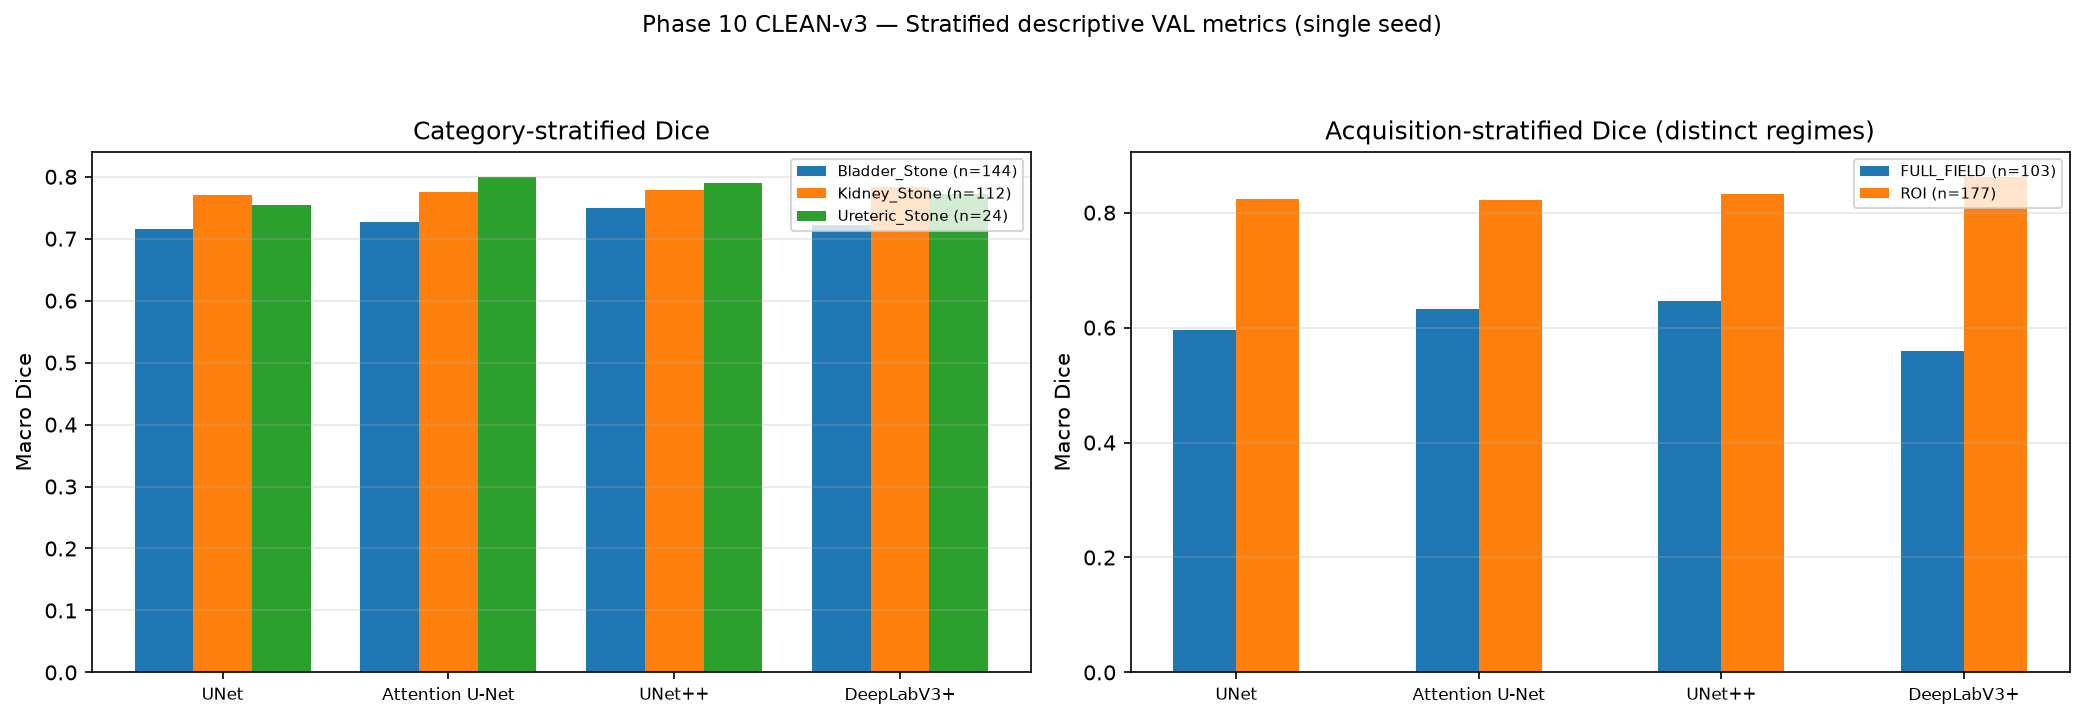

In [16]:
p_strat = fc.plot_stratified(cat, acq)
print('Saved:', p_strat)
from IPython.display import Image as IPImage
display(IPImage(filename=str(p_strat)))


## 19. Descriptive Paired Deltas

`DESCRIPTIVE_SINGLE_SEED_ONLY` — for understanding, **not** inferential claims.
No p-values, no significance stars, no confidence intervals, no "statistically better".


In [17]:
deltas = pd.read_csv(fc.TABLES / 'phase10_clean_v3_pairwise_descriptive_deltas.csv')
display(deltas)
print()
print('STATUS:', deltas['status'].unique().tolist())
assert (deltas['status']=='DESCRIPTIVE_SINGLE_SEED_ONLY').all()
print('No inferential statistics are present.')


,model_a,model_b,mean_paired_dice_diff,median_paired_dice_diff,mean_paired_iou_diff,median_paired_iou_diff,status
0,UNet,Attention U-Net,-0.011881,-1.045322e-09,-0.009540,-1.392544e-09,DESCRIPTIVE_SINGLE_SEED_ONLY
1,UNet,UNet++,-0.023547,-7.944085e-03,-0.027163,-1.141682e-02,DESCRIPTIVE_SINGLE_SEED_ONLY
2,UNet,DeepLabV3+,-0.010296,-1.189758e-02,-0.020664,-1.914380e-02,DESCRIPTIVE_SINGLE_SEED_ONLY
3,Attention U-Net,UNet++,-0.011666,-8.568882e-03,-0.017623,-1.322003e-02,DESCRIPTIVE_SINGLE_SEED_ONLY
4,Attention U-Net,DeepLabV3+,0.001585,-1.149106e-02,-0.011124,-1.755507e-02,DESCRIPTIVE_SINGLE_SEED_ONLY
5,UNet++,DeepLabV3+,0.013251,-5.591699e-03,0.006499,-8.821939e-03,DESCRIPTIVE_SINGLE_SEED_ONLY



STATUS: ['DESCRIPTIVE_SINGLE_SEED_ONLY']
No inferential statistics are present.


Saved: D:\Softfors\jup\reports\figures\phase10_clean_v3_paired_dice_distributions.png


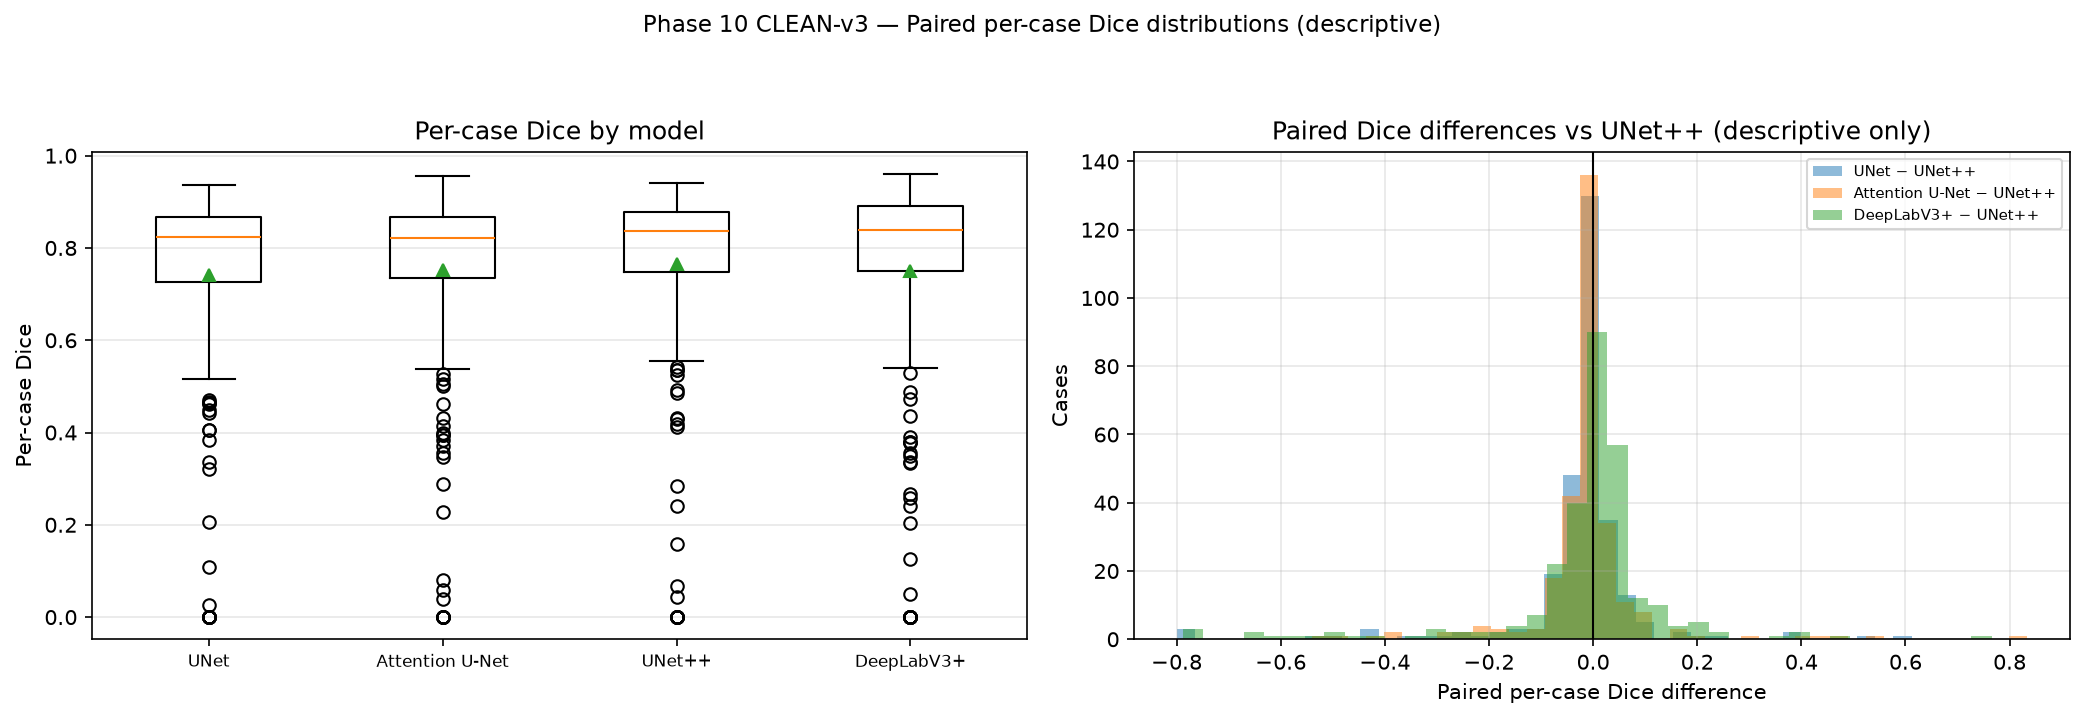

In [18]:
p_dist = fc.plot_paired_distributions(paired)
print('Saved:', p_dist)
display(IPImage(filename=str(p_dist)))


## 20. Case-Wise Agreement / Disagreement Patterns

Descriptive distributions useful for later Phase 11 failure analysis. Not significance.


In [19]:
dis = pd.read_csv(fc.TABLES / 'phase10_clean_v3_pairwise_case_disagreement_summary.csv')
display(dis)
print()
print('Of 280 cases, counts of |Dice difference| > 0.10 show how often model pairs diverge')
print('materially on the SAME case - useful for targeted failure analysis later.')


,model_a,model_b,both_dice_ge_0.5,both_dice_lt_0.5,abs_dice_diff_gt_0.10,a_better_by_gt_0.10,b_better_by_gt_0.10,status
0,UNet,Attention U-Net,245,18,32,13,19,DESCRIPTIVE_SINGLE_SEED_ONLY
1,UNet,UNet++,244,16,32,10,22,DESCRIPTIVE_SINGLE_SEED_ONLY
2,UNet,DeepLabV3+,239,22,50,23,27,DESCRIPTIVE_SINGLE_SEED_ONLY
3,Attention U-Net,UNet++,249,16,33,13,20,DESCRIPTIVE_SINGLE_SEED_ONLY
4,Attention U-Net,DeepLabV3+,243,21,54,22,32,DESCRIPTIVE_SINGLE_SEED_ONLY
5,UNet++,DeepLabV3+,240,17,60,32,28,DESCRIPTIVE_SINGLE_SEED_ONLY



Of 280 cases, counts of |Dice difference| > 0.10 show how often model pairs diverge
materially on the SAME case - useful for targeted failure analysis later.


## 21. Frozen 16-Case Paired Qualitative Comparison

Same canonical 16 cases for all four models (selection SHA verified below).
Identical probability scaling (0–1) and identical overlay semantics across models.

> **DETERMINISTIC_GALLERY_SUBSET_ONLY** — these 16 cases are **not** overall model scores.


In [20]:
gsha = fc.sha256_file(fc.CANONICAL_GALLERY)
print('Canonical gallery SHA :', gsha)
print('Expected SHA          :', fc.CANONICAL_GALLERY_SHA)
assert gsha == fc.CANONICAL_GALLERY_SHA
print('Gallery selection verified - identical to UNet / Attention U-Net / UNet++ / DeepLabV3+')
print()
gal_pages = fc.build_paired_gallery(paired)
print(f'Generated {{len(gal_pages)}} paired gallery pages (one per frozen case)')


Canonical gallery SHA : 10ad09cbcaabb56bc6bc6aefe016c83b2173933bf6d1f16e4baaf3f0845613db
Expected SHA          : 10ad09cbcaabb56bc6bc6aefe016c83b2173933bf6d1f16e4baaf3f0845613db
Gallery selection verified - identical to UNet / Attention U-Net / UNet++ / DeepLabV3+



Generated {len(gal_pages)} paired gallery pages (one per frozen case)


phase10_clean_v3_paired_gallery_case01.png


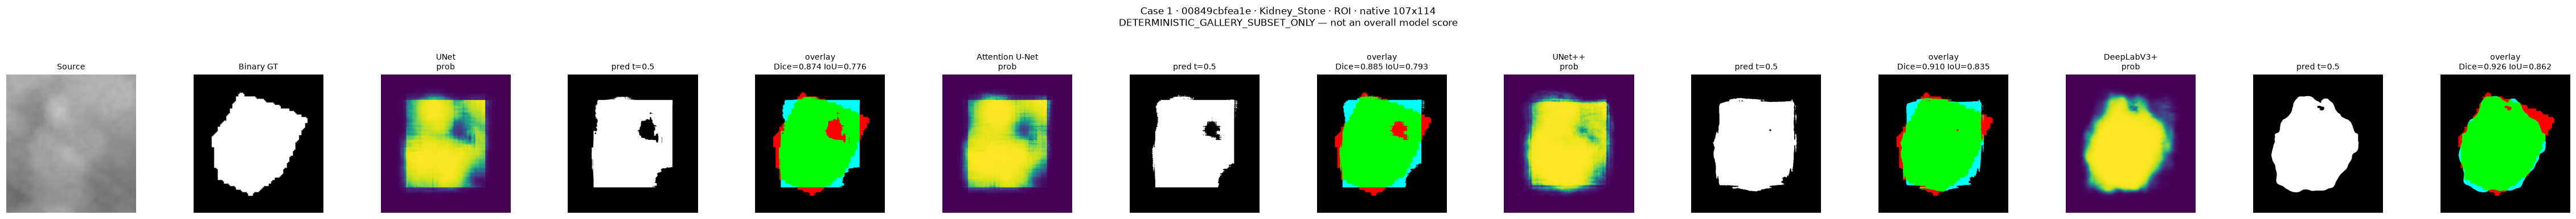

phase10_clean_v3_paired_gallery_case02.png


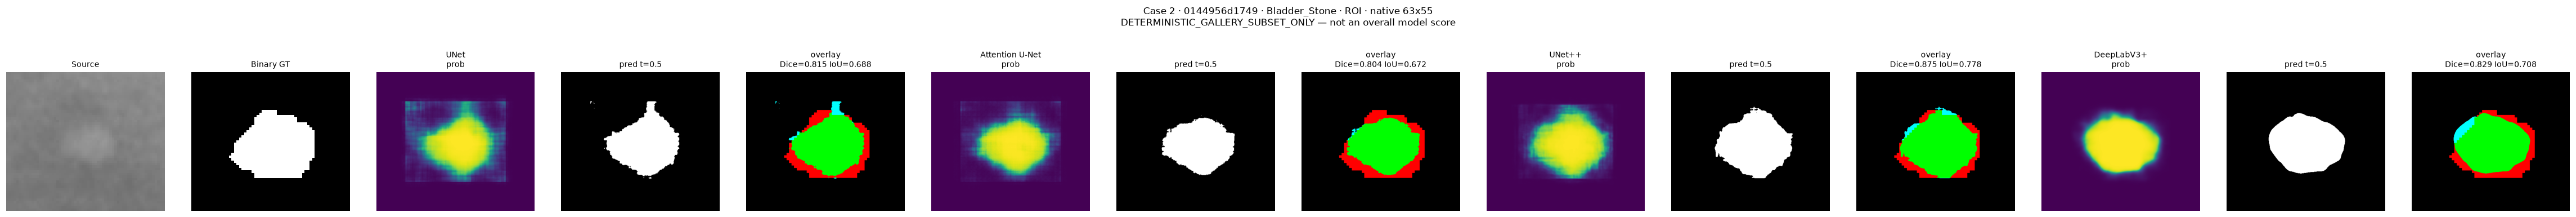

phase10_clean_v3_paired_gallery_case03.png


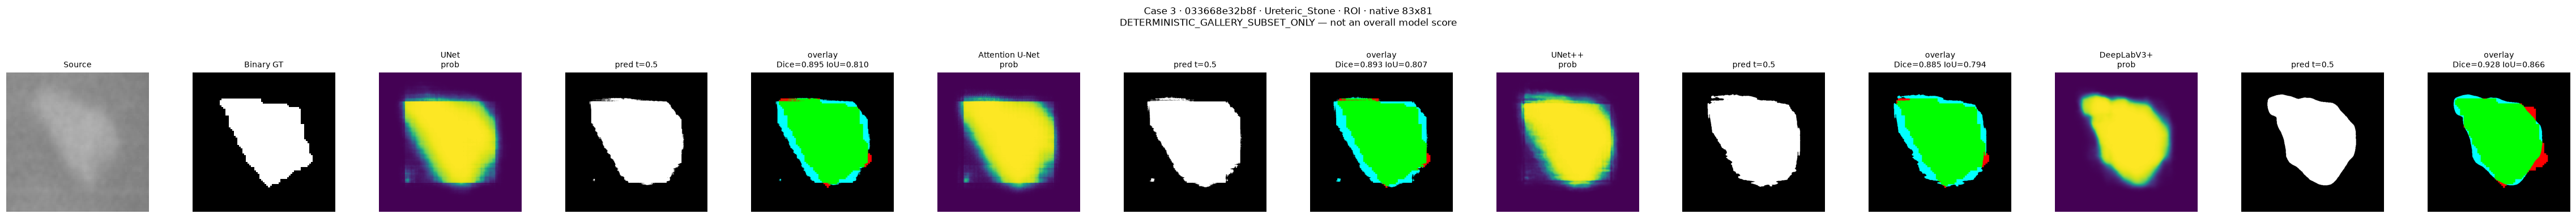

phase10_clean_v3_paired_gallery_case04.png


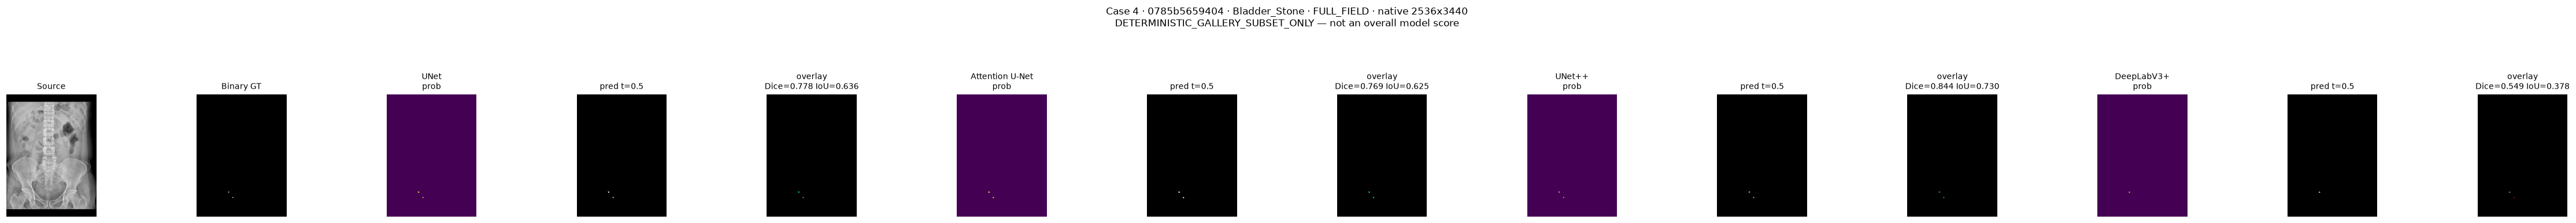

phase10_clean_v3_paired_gallery_case05.png


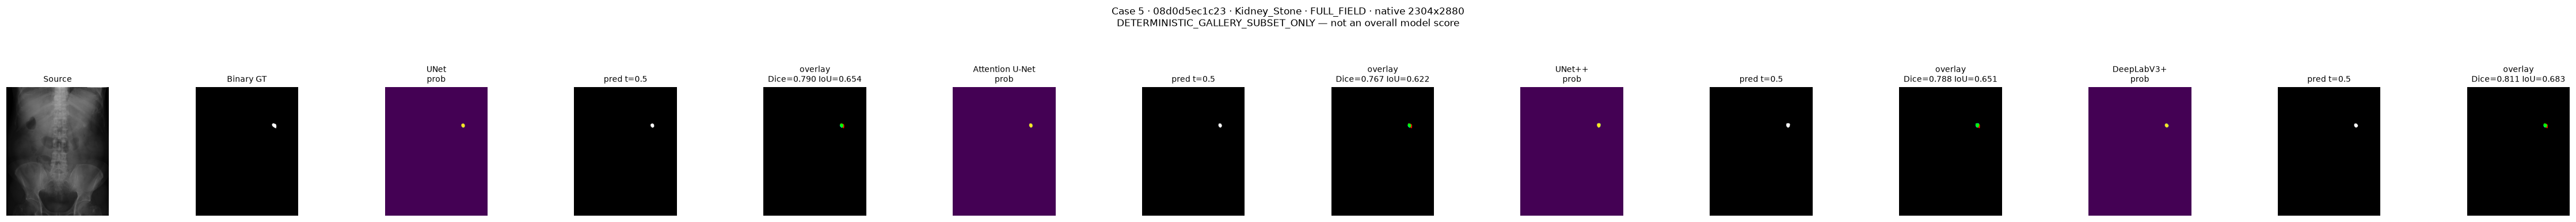

phase10_clean_v3_paired_gallery_case06.png


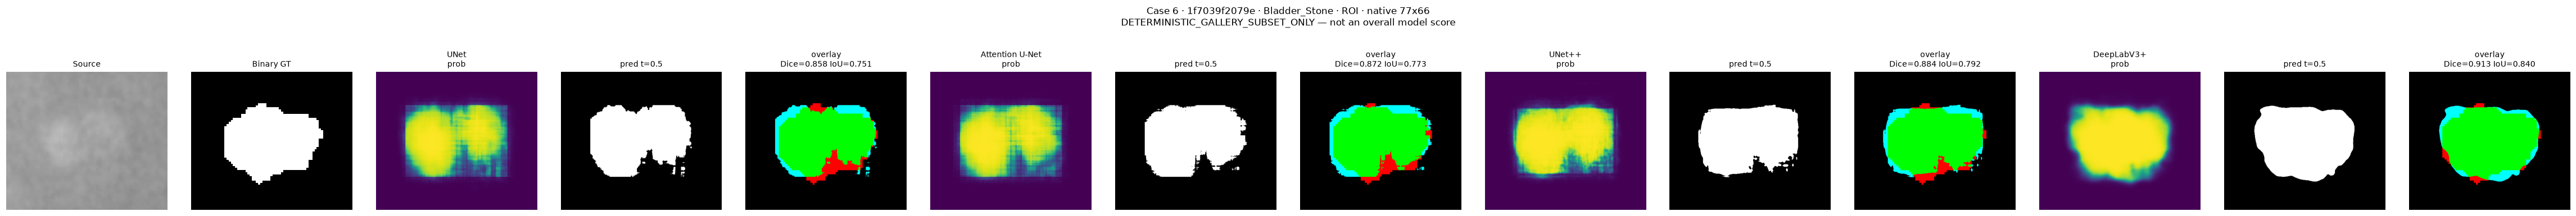

phase10_clean_v3_paired_gallery_case07.png


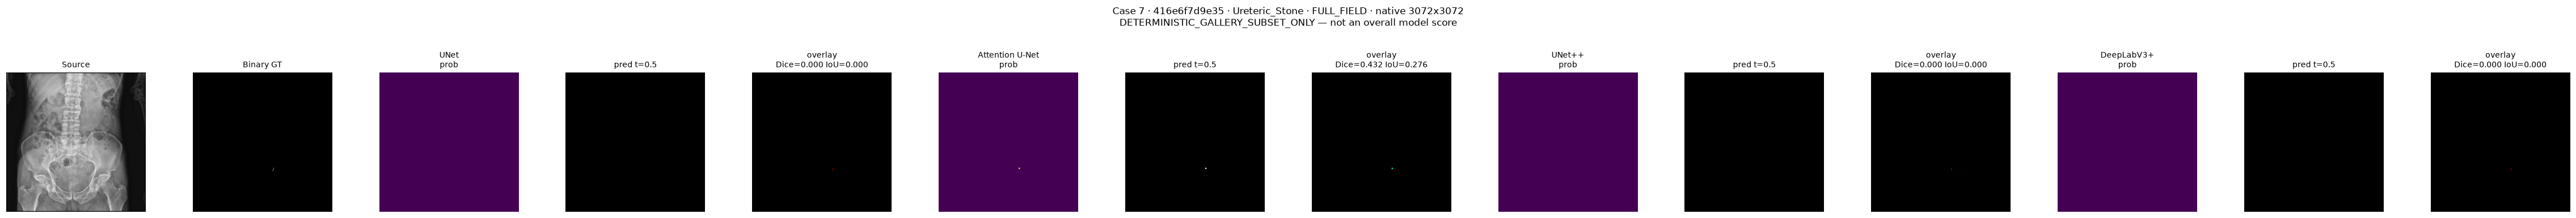

phase10_clean_v3_paired_gallery_case08.png


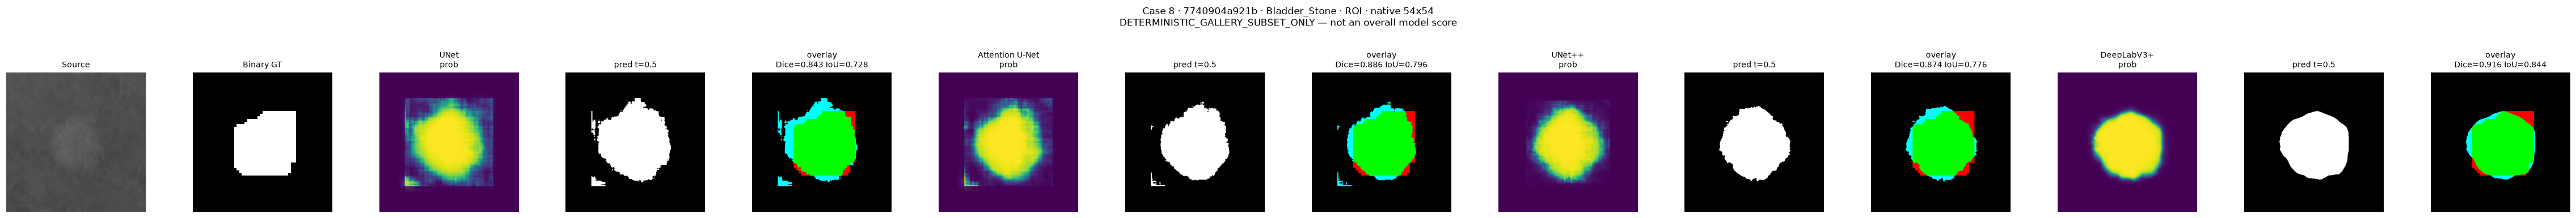

phase10_clean_v3_paired_gallery_case09.png


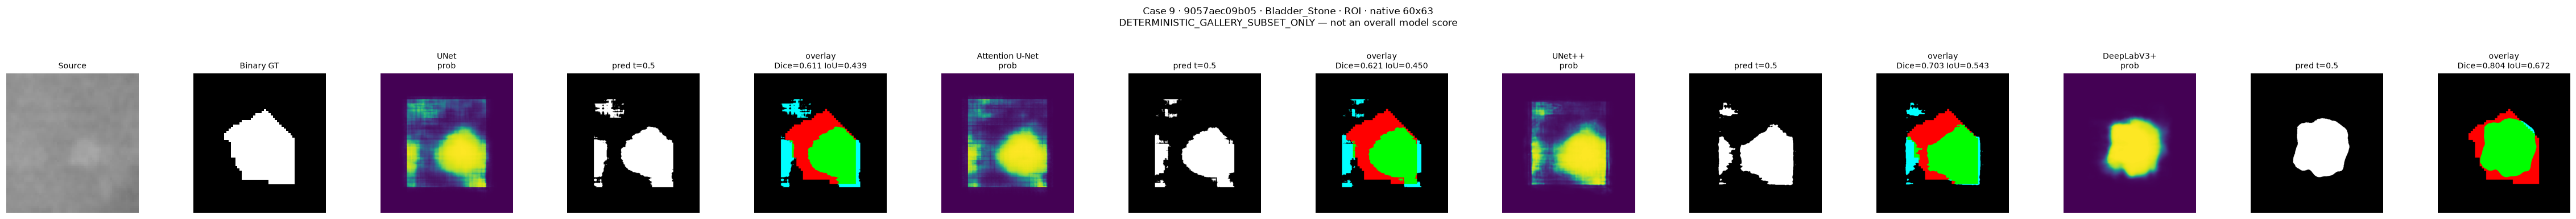

phase10_clean_v3_paired_gallery_case10.png


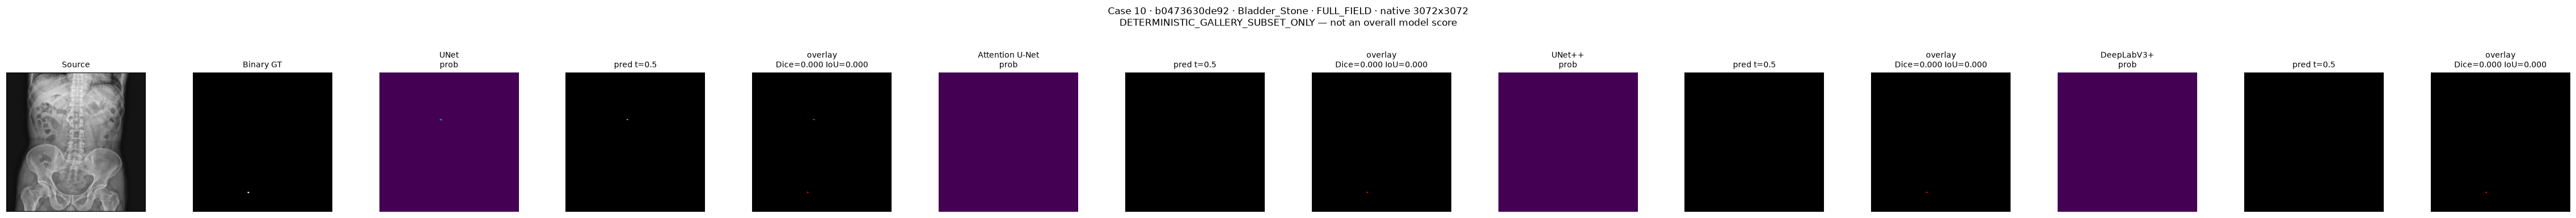

phase10_clean_v3_paired_gallery_case11.png


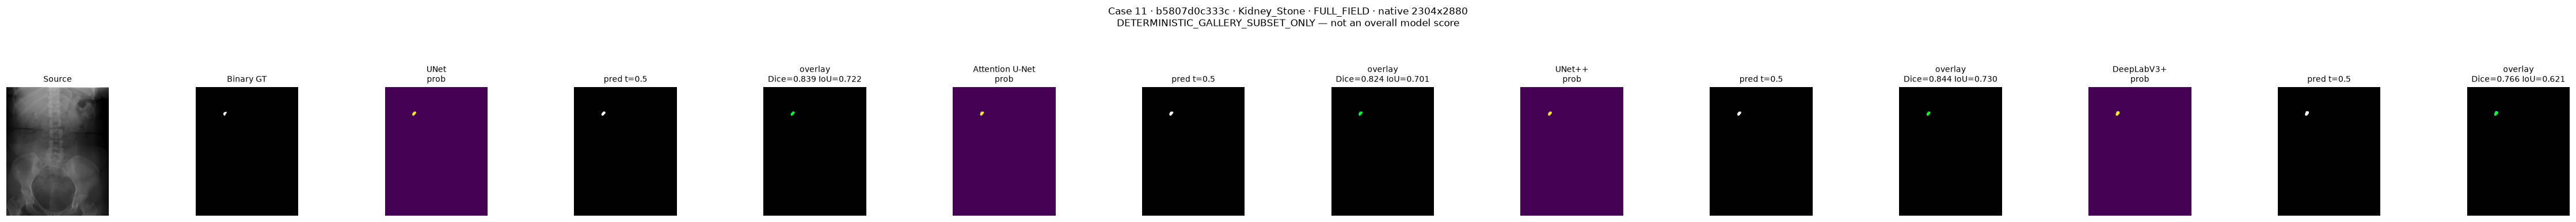

phase10_clean_v3_paired_gallery_case12.png


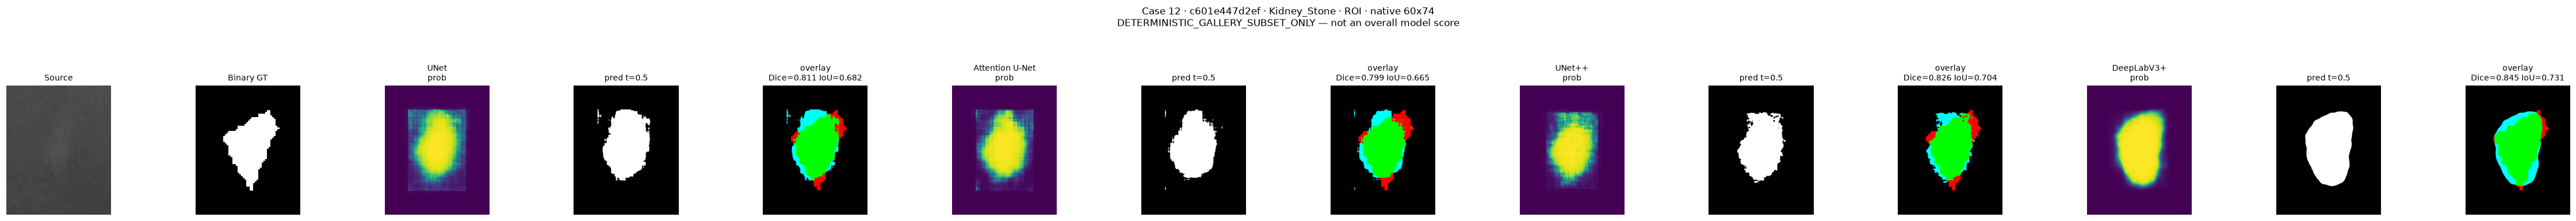

phase10_clean_v3_paired_gallery_case13.png


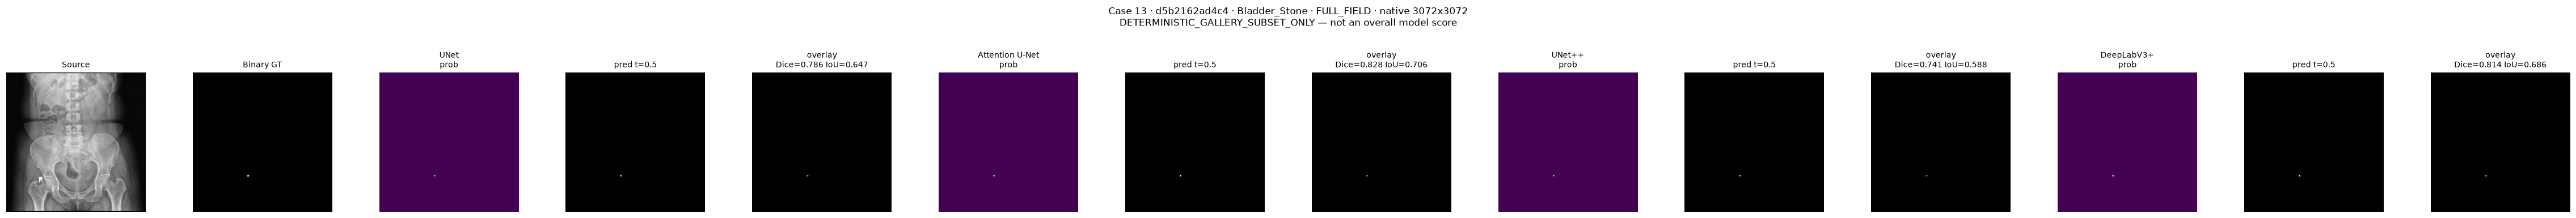

phase10_clean_v3_paired_gallery_case14.png


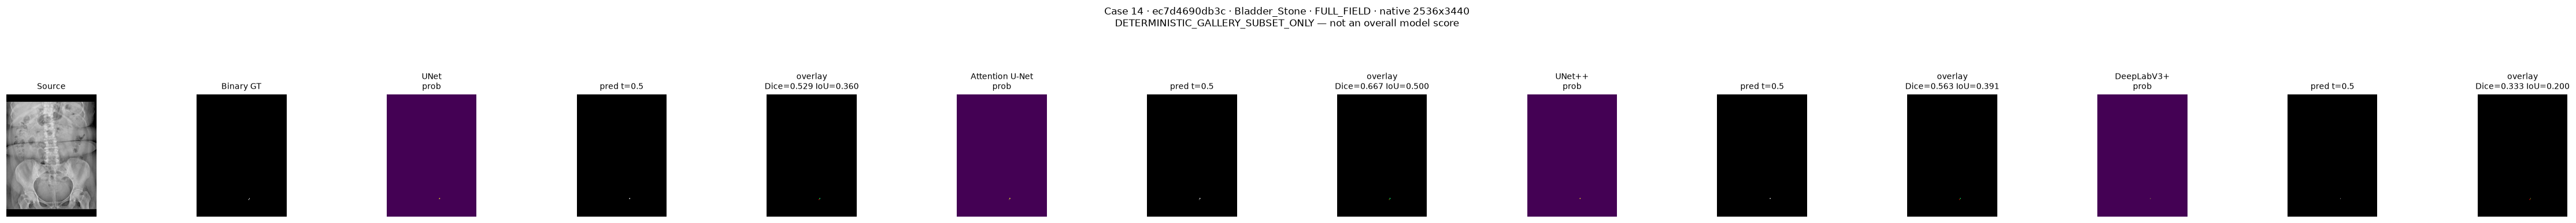

phase10_clean_v3_paired_gallery_case15.png


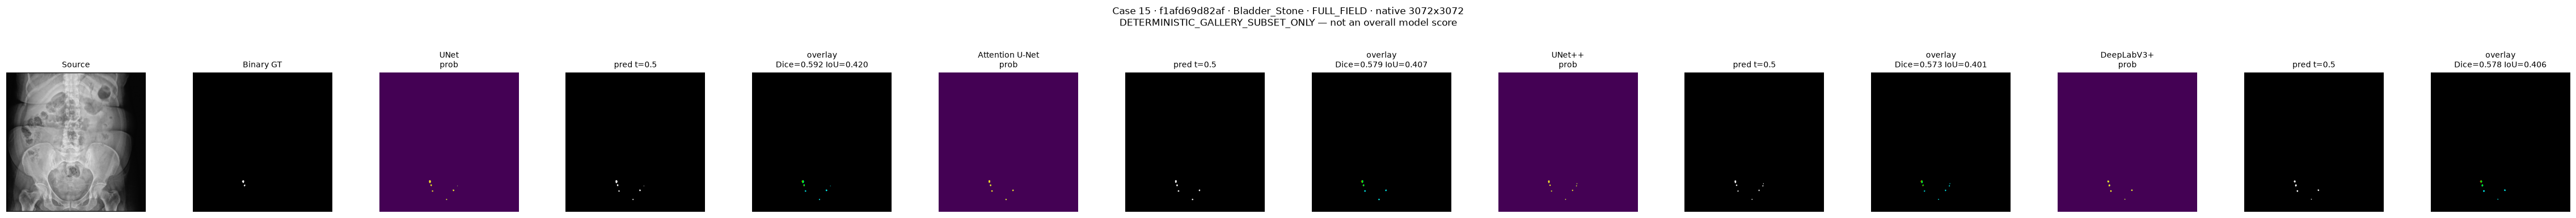

phase10_clean_v3_paired_gallery_case16.png


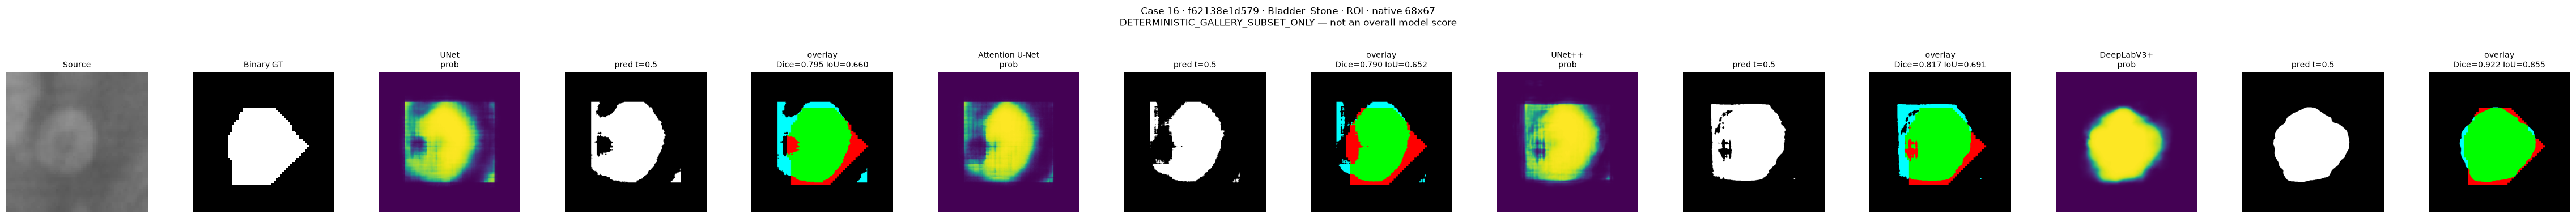

In [21]:
from IPython.display import Image as IPImage
for p in gal_pages:
    print(p.name)
    display(IPImage(filename=str(p)))


## 22. Historical-v2 Separation

Historical Phase-10 results are **HISTORICAL_v2** provenance, produced on contaminated /
different development membership.

| Model | v2 best epoch | v2 VAL Dice | clean-v3 best epoch | clean-v3 VAL Dice |
|---|---|---|---|---|
| Attention U-Net | 77 | 0.7530131340026855 | 54 | 0.7525129853960107 |
| UNet++ | 77 | 0.7625221610069275 | 70 | 0.7641595156062713 |
| DeepLabV3+ | 37 | 0.7487905025482178 | 52 | 0.7509140344161673 |

> Do **not** attribute clean-v3 vs v2 differences solely to leakage remediation — population
> composition also changed (v2 KUB 1979/283 vs v3 1978/280). Do not merge v2 and clean-v3
> tables as if matched. Historical evidence is provenance only.


## 23. Limitations

1. **Single seed (42)** — no reproducibility study (Phase 29) and no significance testing
   (Phase 31). Differences of a few thousandths of Dice are not interpretable.
2. **VAL only (280 KUB cases)** — TEST locked until Phase 39; no generalization claim.
3. **Ureteric_Stone n=24** — small subgroup, unstable.
4. **Acquisition regimes differ** — ROI vs FULL_FIELD must not be pooled.
5. **Gallery (16 cases)** is a deterministic subset, not a score.
6. **DeepLabV3+ config quirk** — `base_channels: 32` present for factory-signature
   compatibility but unused (canonical decoder width 256); expected, not a defect.
7. **fp16 residuals** — paired re-inference (batch 1) vs training-time validation (batch 4,
   AMP fp16) leaves ~1e-6..1e-5 rounding differences.


## 24. Phase-10 Conclusions

**DESCRIPTIVE CLEAN-v3 BASELINE COMPARISON COMPLETE.**

Observed patterns (not rankings):
- All four architectures converge to a broadly similar VAL Dice band (~0.74–0.77).
- **UNet++** attains the highest observed single-seed VAL Dice (0.7642) and the best
  FULL_FIELD Dice among the four; **DeepLabV3+** attains the best ROI Dice.
- **UNet** is lowest on most strata but has the fewest parameters and shortest training.
- Every model performs substantially better on **ROI** crops than on **FULL_FIELD**
  radiographs — a regime effect, consistent with the motivation for regional refinement.
- Ureteric_Stone (n=24) shows the largest spread but is too small to interpret.

**No winner is declared.** These are single-seed descriptive VAL findings; no statistical
significance testing has been performed. Selecting a "best" architecture would require
Phase 29 (three-seed reproducibility) and Phase 31 (significance testing).


## 25. Artifact Registry


In [22]:
def _sh(p): return fc.sha256_file(Path(p))
T = fc.TABLES
reg = []
for k in fc.MODEL_ORDER:
    reg.append({'artifact': f'epoch_results_{k}', 'path': paths[k].name, 'sha256': _sh(paths[k])})
reg += [
 {'artifact':'all_models_epoch_results_long','path': lp.name,'sha256': _sh(lp)},
 {'artifact':'paired_val_case_metrics','path':'phase10_clean_v3_paired_val_case_metrics.csv','sha256': _sh(T/'phase10_clean_v3_paired_val_case_metrics.csv')},
 {'artifact':'overall_baseline_comparison','path':'phase10_clean_v3_overall_baseline_comparison.csv','sha256': _sh(T/'phase10_clean_v3_overall_baseline_comparison.csv')},
 {'artifact':'category_stratified_metrics','path':'phase10_clean_v3_category_stratified_metrics.csv','sha256': _sh(T/'phase10_clean_v3_category_stratified_metrics.csv')},
 {'artifact':'acquisition_stratified_metrics','path':'phase10_clean_v3_acquisition_stratified_metrics.csv','sha256': _sh(T/'phase10_clean_v3_acquisition_stratified_metrics.csv')},
 {'artifact':'pairwise_descriptive_deltas','path':'phase10_clean_v3_pairwise_descriptive_deltas.csv','sha256': _sh(T/'phase10_clean_v3_pairwise_descriptive_deltas.csv')},
 {'artifact':'pairwise_case_disagreement_summary','path':'phase10_clean_v3_pairwise_case_disagreement_summary.csv','sha256': _sh(T/'phase10_clean_v3_pairwise_case_disagreement_summary.csv')},
 {'artifact':'fig_training_dynamics','path': p_dyn.name,'sha256': _sh(p_dyn)},
 {'artifact':'fig_stratified_metrics','path': p_strat.name,'sha256': _sh(p_strat)},
 {'artifact':'fig_paired_dice_distributions','path': p_dist.name,'sha256': _sh(p_dist)},
 {'artifact':'support_code','path':'phase10_final_comparison.py','sha256': _sh(PROJECT_ROOT/'notebooks'/'phasewise'/'phase_10_baseline_comparison'/'code'/'phase10_final_comparison.py')},
]
for i, p in enumerate(gal_pages, start=1):
    reg.append({'artifact': f'gallery_case_{i:02d}', 'path': p.name, 'sha256': _sh(p)})
REG = pd.DataFrame(reg)
rp = T / 'phase10_clean_v3_final_comparison_artifact_registry.csv'
REG.to_csv(rp, index=False)
print(f'Saved registry: {{rp.name}} ({{len(REG)}} entries)')
display(REG)


Saved registry: {rp.name} ({len(REG)} entries)


,artifact,path,sha256
0,epoch_results_unet,phase10_final_epoch_results_unet.csv,484d27507bd0493235a5fd889943b29101fabc0c5b2e1e7ca3f4541cf9df2ba8
1,epoch_results_attention_unet,phase10_final_epoch_results_attention_unet.csv,2aecdb5e4fcb8cae1fa09864e17bbe5f50afe9d40ff09794364456d086255fd2
2,epoch_results_unetpp,phase10_final_epoch_results_unetpp.csv,2dd885d27788e5981a9356cf3e1f518d55eaff61d34f061eee92660beed505d4
3,epoch_results_deeplabv3plus,phase10_final_epoch_results_deeplabv3plus.csv,f0f5750025d0cfb8706c35958d3e76b28a3246105184bd715e161332bfcd19a2
4,all_models_epoch_results_long,phase10_final_all_models_epoch_results_long.csv,9057cdd428995b88bf0c527152d072398573892649baebea5b4082de2b6476ca
5,paired_val_case_metrics,phase10_clean_v3_paired_val_case_metrics.csv,61fbaf34ea404eb3de6cf4c70d0b507dfa3466598ca6515c915abea016acddaa
6,overall_baseline_comparison,phase10_clean_v3_overall_baseline_comparison.csv,48a3e9c0be018e51d461f64755680ef0fd7d990b056e3453f4f48923791497c4
7,category_stratified_metrics,phase10_clean_v3_category_stratified_metrics.csv,82bb9ab462d772c3869c322954935c45c86bc0d4925a8604fea994ad2f049f35
8,acquisition_stratified_metrics,phase10_clean_v3_acquisition_stratified_metrics.csv,9b198c625107dd48e36239a72aca1a140dd262a62cfc6100616b41902e4569a1
9,pairwise_descriptive_deltas,phase10_clean_v3_pairwise_descriptive_deltas.csv,38affb05885b64652592f01c429606e6a003f0c114b8bed9e180a30898d56537


## 26. Phase-11 Boundary

Phase 10 is closed by this comparison. **Phase 11 is NOT started.**


In [23]:
print('=== PHASE-10 CLOSURE BOUNDARY ===')
print('Training epochs in this notebook : 0')
print('Optimizer steps                  : 0')
print('Checkpoint writes                : 0')
print('Config / history changes         : 0')
print('TEST image reads / mask reads    : 0 / 0')
print('TEST metrics / visualizations    : 0 / 0')
print('Statistical testing performed    : NO')
print('Winner declared                  : NO')
print('Phase 11 started                 : NO')
print()
print('NEXT: WAIT_FOR_SUPERVISOR_PHASE11_AUTHORIZATION')


=== PHASE-10 CLOSURE BOUNDARY ===
Training epochs in this notebook : 0
Optimizer steps                  : 0
Checkpoint writes                : 0
Config / history changes         : 0
TEST image reads / mask reads    : 0 / 0
TEST metrics / visualizations    : 0 / 0
Statistical testing performed    : NO
Winner declared                  : NO
Phase 11 started                 : NO

NEXT: WAIT_FOR_SUPERVISOR_PHASE11_AUTHORIZATION


## Descriptive Evaluation and Visual Evidence — Phase 10 (four-model comparison)

**Metric source / provenance.** Central post-audit artifacts
(`project_evaluation_segmentation_summary.csv`,
`project_evaluation_confusion_matrices.json`,
`project_evaluation_paired_comparisons.csv`) plus the saved clean-v3 paired
per-case table (`phase10_clean_v3_paired_val_case_metrics.csv`). No inference.

**Model-identity match (critical).** The central `GLOBAL` arm is
**`phase10_kub_unetpp_seed42_512_clean_v3` (UNet++, epoch 70)**. Pixel confusion,
boundary and calibration metrics from the audit therefore apply **only to UNet++**.
The other three models (UNet, Attention U-Net, DeepLabV3+) have no persisted
per-pixel maps, so those metric families are `UNAVAILABLE_FROM_SAVED_ARTIFACTS`
for them — no metric is borrowed across models.

**What this section does NOT prove.** Single-seed (42) descriptive VAL evidence.
No winner is declared; no significance testing was performed (Phases 29/31 have
not run). TEST remains locked.

,artifact,sha256
0,project_evaluation_segmentation_summary.csv,d7cda533740600f4
1,project_evaluation_confusion_matrices.json,64c32e8e858eac8d
2,project_evaluation_paired_comparisons.csv,d21254793973b1ed
3,phase10_clean_v3_paired_val_case_metrics.csv,61fbaf34ea404eb3


,model,metric_domain,label,pooled_dice,pooled_iou,pooled_precision,pooled_recall,pooled_specificity,pooled_balanced_accuracy,pooled_mcc,pooled_cohen_kappa,pooled_tp,pooled_tn,pooled_fp,pooled_fn,image_mean_hd95,image_mean_assd,image_mean_surface_dice,brier,ece,roc_auc,average_precision,dice_ci_low,dice_ci_high
0,UNet++ (GLOBAL arm),PIXEL_SEGMENTATION,DESCRIPTIVE_SUPPORTING_METRIC__NOT_PROSPECTIVE_GATE,0.665747,0.498966,0.790486,0.57501,0.999883,0.787446,0.673986,0.665531,358396,814085530,94991,264891,332.727336,106.590591,0.35072,0.000401,0.000369,0.827385,0.57924,0.581571,0.686591


,model,n,mean_dice,mean_iou,mean_precision,mean_recall,metric_domain,label
0,unet,280,0.740613,0.625382,0.770718,0.783944,PIXEL_SEGMENTATION,DESCRIPTIVE_SUPPORTING_METRIC__NOT_PROSPECTIVE_GATE
1,attention_unet,280,0.752494,0.634922,0.772896,0.792226,PIXEL_SEGMENTATION,DESCRIPTIVE_SUPPORTING_METRIC__NOT_PROSPECTIVE_GATE
2,unetpp,280,0.764160,0.652545,0.799681,0.791240,PIXEL_SEGMENTATION,DESCRIPTIVE_SUPPORTING_METRIC__NOT_PROSPECTIVE_GATE
3,deeplabv3plus,280,0.750909,0.646046,0.794324,0.782298,PIXEL_SEGMENTATION,DESCRIPTIVE_SUPPORTING_METRIC__NOT_PROSPECTIVE_GATE


,model,confusion_matrix,boundary,calibration,reason
0,UNet++,YES,YES,YES,GLOBAL arm of the central safe replay
1,UNet,UNAVAILABLE_FROM_SAVED_ARTIFACTS,UNAVAILABLE_FROM_SAVED_ARTIFACTS,UNAVAILABLE_FROM_SAVED_ARTIFACTS,no persisted per-pixel maps for this model
2,Attention U-Net,UNAVAILABLE_FROM_SAVED_ARTIFACTS,UNAVAILABLE_FROM_SAVED_ARTIFACTS,UNAVAILABLE_FROM_SAVED_ARTIFACTS,no persisted per-pixel maps for this model
3,DeepLabV3+,UNAVAILABLE_FROM_SAVED_ARTIFACTS,UNAVAILABLE_FROM_SAVED_ARTIFACTS,UNAVAILABLE_FROM_SAVED_ARTIFACTS,no persisted per-pixel maps for this model


C:\Users\user\AppData\Local\Temp\ipykernel_12120\3384410866.py:90: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  _plt.savefig(str(_p), dpi=150, bbox_inches='tight'); _plt.show(); _show(_p)


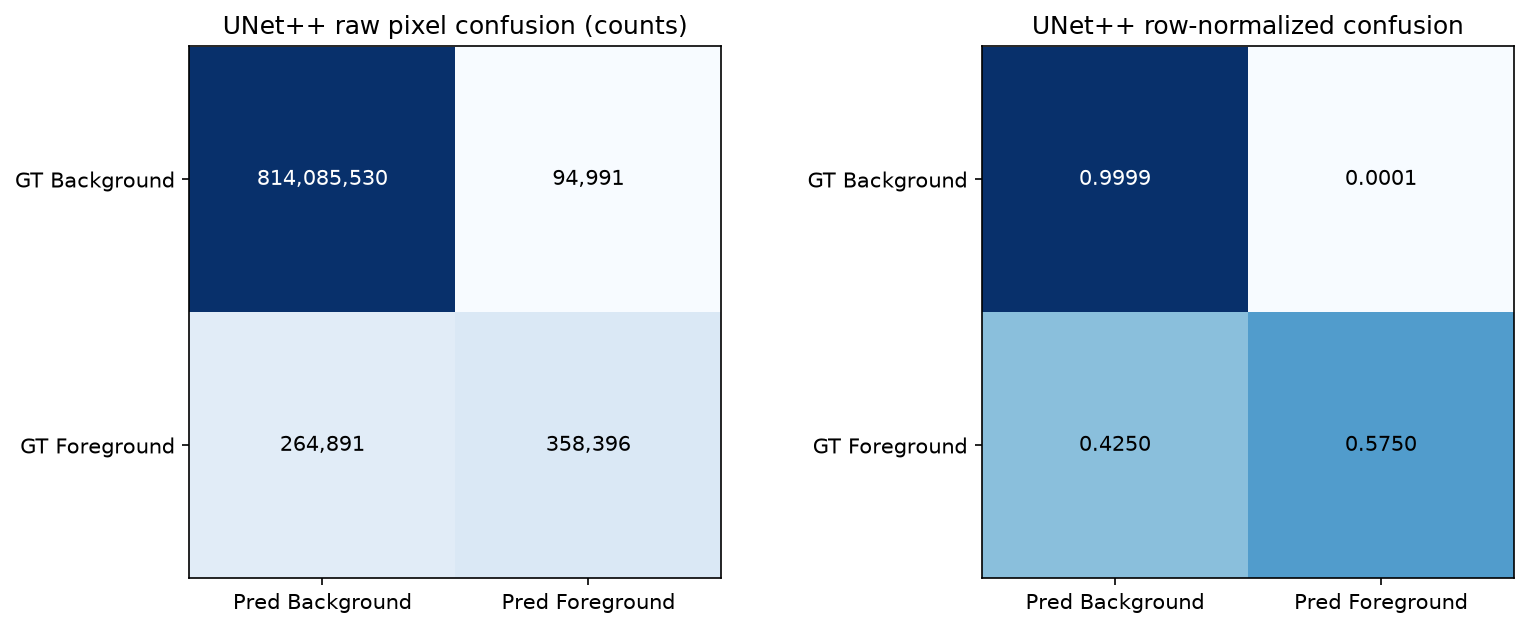

C:\Users\user\AppData\Local\Temp\ipykernel_12120\3384410866.py:100: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  _plt.savefig(str(_p), dpi=150, bbox_inches='tight'); _plt.show(); _show(_p)


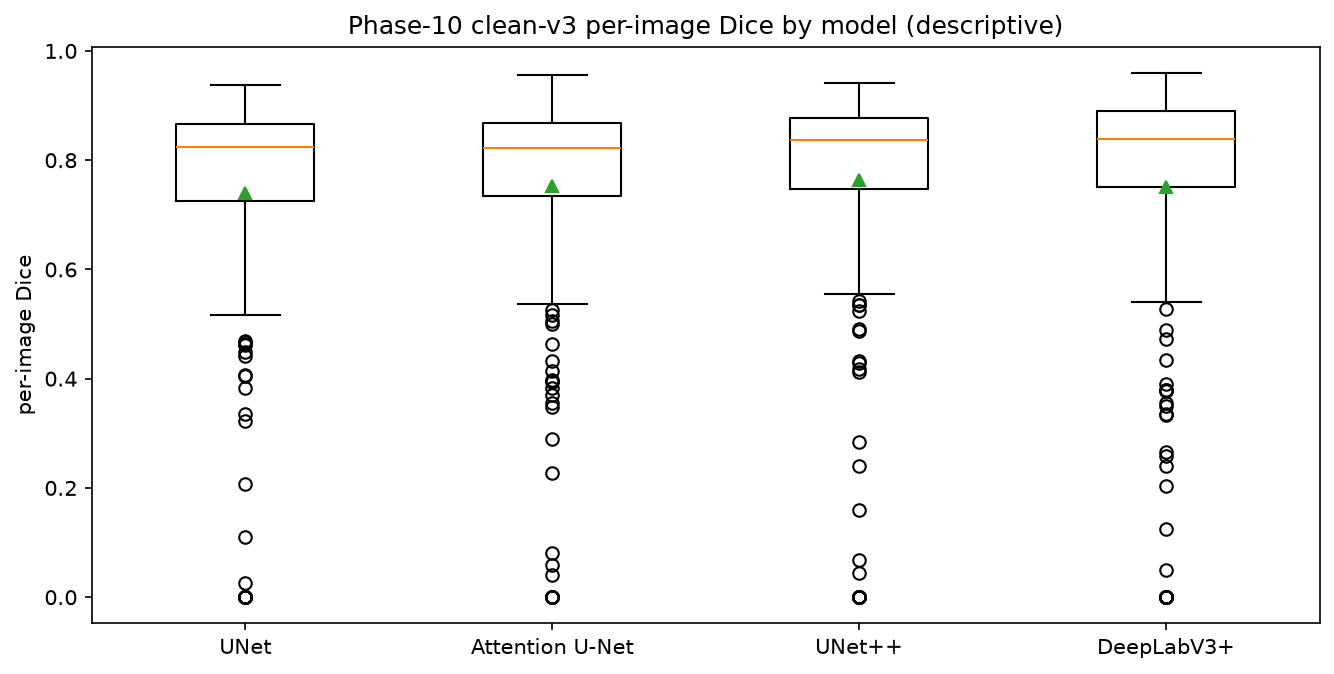

,comparison,metric,n_pairs,mean_difference,ci_low,ci_high,label
0,H3_DOWNSTREAM - GLOBAL,dice,103,-0.247290,-0.292163,-0.200407,DESCRIPTIVE_POST_HOC_STATISTICAL_SUPPORT
1,PREDICTED_REGIONAL - GLOBAL,dice,103,-0.217386,-0.258527,-0.175111,DESCRIPTIVE_POST_HOC_STATISTICAL_SUPPORT
2,H3_DOWNSTREAM - PREDICTED_REGIONAL,dice,103,-0.029903,-0.051138,-0.008397,DESCRIPTIVE_POST_HOC_STATISTICAL_SUPPORT
3,ORACLE_REGIONAL - GLOBAL,dice,103,0.166499,0.124279,0.213573,DESCRIPTIVE_POST_HOC_STATISTICAL_SUPPORT


All values above are DESCRIPTIVE_SUPPORTING_METRIC__NOT_PROSPECTIVE_GATE | paired statistics are DESCRIPTIVE_POST_HOC_STATISTICAL_SUPPORT


In [24]:
# ── Phasewise evaluation / visualization synchronization (post-audit) ─────────
import json as _json, hashlib as _hashlib
from pathlib import Path as _Path
import numpy as _np
import pandas as _pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as _plt
try:
    from IPython.display import display as _disp, Image as _Img
except Exception:
    _disp = print; _Img = None
_ROOT = _Path('D:/Softfors/jup')
_AUD = _ROOT / 'reports' / 'audits'
_TAB = _ROOT / 'reports' / 'tables'
_FIG = _ROOT / 'reports' / 'figures' / 'phasewise_sync'
_FIG.mkdir(parents=True, exist_ok=True)
def _sha(p): return _hashlib.sha256(_Path(p).read_bytes()).hexdigest()
def _load(p): return _json.loads(_Path(p).read_text(encoding='utf-8'))
def _show(p, w=840):
    if _Img is not None and _Path(p).exists():
        _disp(_Img(filename=str(p), width=w))
LBL      = 'DESCRIPTIVE_SUPPORTING_METRIC__NOT_PROSPECTIVE_GATE'
LBL_H3   = 'DESCRIPTIVE_SUPPORTING_METRIC__NOT_H3_GATE'
LBL_STAT = 'DESCRIPTIVE_POST_HOC_STATISTICAL_SUPPORT'

prov = [
    ('project_evaluation_segmentation_summary.csv', _TAB / 'project_evaluation_segmentation_summary.csv'),
    ('project_evaluation_confusion_matrices.json', _TAB / 'project_evaluation_confusion_matrices.json'),
    ('project_evaluation_paired_comparisons.csv', _TAB / 'project_evaluation_paired_comparisons.csv'),
    ('phase10_clean_v3_paired_val_case_metrics.csv', _TAB / 'phase10_clean_v3_paired_val_case_metrics.csv'),
]
_disp(_pd.DataFrame([{'artifact': n, 'sha256': _sha(p)[:16]} for n, p in prov if p.exists()]))

summ = _pd.read_csv(_TAB / 'project_evaluation_segmentation_summary.csv')
g = summ[summ['arm'] == 'GLOBAL'].iloc[0]
cols = ['pooled_dice', 'pooled_iou', 'pooled_precision', 'pooled_recall', 'pooled_specificity',
        'pooled_balanced_accuracy', 'pooled_mcc', 'pooled_cohen_kappa', 'pooled_tp', 'pooled_tn',
        'pooled_fp', 'pooled_fn', 'image_mean_hd95', 'image_mean_assd', 'image_mean_surface_dice',
        'brier', 'ece', 'roc_auc', 'average_precision', 'dice_ci_low', 'dice_ci_high']
row = {'model': 'UNet++ (GLOBAL arm)', 'metric_domain': 'PIXEL_SEGMENTATION', 'label': LBL}
row.update({c: g[c] for c in cols})
_disp(_pd.DataFrame([row]).round(6))

paired = _pd.read_csv(_TAB / 'phase10_clean_v3_paired_val_case_metrics.csv')
rows = []
for m in ['unet', 'attention_unet', 'unetpp', 'deeplabv3plus']:
    rows.append({'model': m, 'n': int(paired[f'{m}_dice'].notna().sum()),
                 'mean_dice': float(paired[f'{m}_dice'].mean()),
                 'mean_iou': float(paired[f'{m}_iou'].mean()),
                 'mean_precision': float(paired[f'{m}_precision'].mean()),
                 'mean_recall': float(paired[f'{m}_recall'].mean()),
                 'metric_domain': 'PIXEL_SEGMENTATION', 'label': LBL})
_disp(_pd.DataFrame(rows).round(6))

avail = _pd.DataFrame([
    {'model': 'UNet++', 'confusion_matrix': 'YES', 'boundary': 'YES', 'calibration': 'YES',
     'reason': 'GLOBAL arm of the central safe replay'},
    {'model': 'UNet', 'confusion_matrix': 'UNAVAILABLE_FROM_SAVED_ARTIFACTS', 'boundary': 'UNAVAILABLE_FROM_SAVED_ARTIFACTS',
     'calibration': 'UNAVAILABLE_FROM_SAVED_ARTIFACTS', 'reason': 'no persisted per-pixel maps for this model'},
    {'model': 'Attention U-Net', 'confusion_matrix': 'UNAVAILABLE_FROM_SAVED_ARTIFACTS', 'boundary': 'UNAVAILABLE_FROM_SAVED_ARTIFACTS',
     'calibration': 'UNAVAILABLE_FROM_SAVED_ARTIFACTS', 'reason': 'no persisted per-pixel maps for this model'},
    {'model': 'DeepLabV3+', 'confusion_matrix': 'UNAVAILABLE_FROM_SAVED_ARTIFACTS', 'boundary': 'UNAVAILABLE_FROM_SAVED_ARTIFACTS',
     'calibration': 'UNAVAILABLE_FROM_SAVED_ARTIFACTS', 'reason': 'no persisted per-pixel maps for this model'},
])
_disp(avail)

conf = _load(_TAB / 'project_evaluation_confusion_matrices.json')
gc = conf['GLOBAL']
fig, axes = _plt.subplots(1, 2, figsize=(11, 4.3))
m_raw = _np.array(gc['matrix_raw'], dtype=float)
axes[0].imshow(_np.log10(m_raw + 1), cmap='Blues')
for i in range(2):
    for j in range(2):
        axes[0].text(j, i, f'{int(m_raw[i, j]):,}', ha='center', va='center', fontsize=10,
                     color='black' if m_raw[i, j] < m_raw.max() * 0.6 else 'white')
axes[0].set_xticks([0, 1]); axes[0].set_xticklabels(['Pred Background', 'Pred Foreground'])
axes[0].set_yticks([0, 1]); axes[0].set_yticklabels(['GT Background', 'GT Foreground'])
axes[0].set_title('UNet++ raw pixel confusion (counts)')
m_norm = _np.array(gc['matrix_row_normalized'], dtype=float)
axes[1].imshow(m_norm, cmap='Blues', vmin=0, vmax=1)
for i in range(2):
    for j in range(2):
        axes[1].text(j, i, f'{m_norm[i, j]:.4f}', ha='center', va='center', fontsize=10,
                     color='black' if m_norm[i, j] < 0.6 else 'white')
axes[1].set_xticks([0, 1]); axes[1].set_xticklabels(['Pred Background', 'Pred Foreground'])
axes[1].set_yticks([0, 1]); axes[1].set_yticklabels(['GT Background', 'GT Foreground'])
axes[1].set_title('UNet++ row-normalized confusion')
_plt.tight_layout(); _p = _FIG / 'phase10_unetpp_confusion.png'
_plt.savefig(str(_p), dpi=150, bbox_inches='tight'); _plt.show(); _show(_p)

fig, ax = _plt.subplots(figsize=(9, 4.6))
data = [paired[f'{m}_dice'].dropna().astype(float) for m in ['unet', 'attention_unet', 'unetpp', 'deeplabv3plus']]
try:
    ax.boxplot(data, tick_labels=['UNet', 'Attention U-Net', 'UNet++', 'DeepLabV3+'], showmeans=True)
except TypeError:
    ax.boxplot(data, labels=['UNet', 'Attention U-Net', 'UNet++', 'DeepLabV3+'], showmeans=True)
ax.set_ylabel('per-image Dice'); ax.set_title('Phase-10 clean-v3 per-image Dice by model (descriptive)')
_plt.tight_layout(); _p = _FIG / 'phase10_per_image_dice_by_model.png'
_plt.savefig(str(_p), dpi=150, bbox_inches='tight'); _plt.show(); _show(_p)

pc = _pd.read_csv(_TAB / 'project_evaluation_paired_comparisons.csv')
_disp(pc[['comparison', 'metric', 'n_pairs', 'mean_difference', 'ci_low', 'ci_high', 'label']])
print('All values above are', LBL, '| paired statistics are', LBL_STAT)